# 31 – Bayes-Diagnose je HAST: welcher Fehler passt zu den Symptomen?

**Zweck:** Für jede HAST aus den Zählerdaten ablesen, welche **Symptome** sie zeigt, und daraus mit dem
Satz von Bayes eine Wahrscheinlichkeit je **Fehlerart** ausrechnen, zum Beispiel
„Ventil/Stellantrieb 70 %, Volumenstrom/Hydraulik 20 %“. Die Frage:

> **Welche Fehlerart erklärt die Messdaten einer Station am besten, und wie sicher ist das?**

**Warum dieser Ansatz** (was die bisherigen Notebooks gezeigt haben)

| Befund | Notebook | Folge hier |
|---|---|---|
| Labels taugen nicht zum Trainieren: rund 49 Labels, Label-Leakage; die automatische Kodierung vermischt Befund, Maßnahme und Zeitpunkt | ML-Klassifikator, 15 | **kein gelerntes Modell**; die Begehungen liefern nur Häufigkeiten und den Lösungsschlüssel |
| Keine klaren Stationstypen (Silhouette unter 0,25) | 01, 04, 06 | keine Typen, sondern Symptome je Station |
| Netz-Nachbarn verhalten sich bei Rücklauf und Wassermenge nicht ähnlicher als Zufallspaare (r ≈ 0,04 bis 0,05) | 17 (§ 15/16), GNN-Entwurf | jede Station für sich, kein Netzmodell |
| NB 17 findet Veränderungen, aber keine dauerhaft schlechten Stationen | 17 | die Symptome beschreiben den **Zustand** über ein Jahr, nicht nur die Änderung |
| Ein Isolation Forest auf Stationsprofilen setzte den Ventilfall vor der Reparatur auf Platz 1 von 74 | Chat-Session | Stationsprofile tragen die Information, es fehlt nur die Zuordnung zu einer Ursache |

**Die Idee: wie beim Arzt**

- **Symptome** (Fieber, Husten) → hier zwölf Auffälligkeiten in den Zählerdaten (Abschnitt 5), jede ja/nein.
- **Wissen, welche Krankheit welche Symptome macht** → die **Fehler-Symptom-Matrix**: „Wenn das Ventil hängt,
  wie oft ist der Rücklauf dauerhaft warm?“ Das ist Physik und Erfahrung der ÜZ, nicht aus den Begehungen
  gelernt.
- **Wissen, wie häufig jede Krankheit ist** → das **Vorwissen** aus den Befunden der Begehungen.

Daraus rechnet Naive Bayes mit binären Symptomen s_j ∈ {0, 1}:

  P(F | S) ∝ P(F) · ∏_j P(s_j = 1 | F)^{s_j} · (1 − P(s_j = 1 | F))^{1 − s_j}

- 11 Klassen: 10 Fehlerarten und „kein Fehler“. Sie schließen sich aus, die Ausgabe summiert sich auf 100 %
  und meint die **Hauptursache**.
- Ein Symptom, das sich nicht berechnen lässt (zu wenig Daten, kein Anschlusswert), fällt aus dem Produkt.
- Gerechnet wird in Logarithmen, damit das Produkt kleiner Zahlen nicht auf null fällt.

**Warum die Matrix nicht aus den Begehungen berechnet wird:** Sonst prüft sich das Modell an genau den Daten,
aus denen es gebaut wurde. Die Begehungen bleiben der **Lösungsschlüssel** (Abschnitt 10).

**Ehrlich vorweg**
- Die Matrix ist ein **Entwurf aus der Physik**, noch nicht mit der ÜZ abgestimmt. Die Wahrscheinlichkeiten
  sind genau so gut wie diese Matrix.
- Das Ergebnis ist eine **Prüfreihenfolge** mit Begründung, keine Diagnose im Sinne eines Befunds vor Ort.

**Eingaben**

| Datei | Wofür |
|---|---|
| `data/processed/real_meters/*.csv` | Stundenraster je Zähler aus NB 00 (Zählerstände, Durchfluss, Leistung, Temperaturen) |
| `external/dwd/…` | Tagesmitteltemperatur DWD Kitzingen (wie NB 06) |
| `data/raw/Nodes_Edges.ods`, `data/raw/Zuordnung.xlsx` | Anschlusswert; Adresse → Zählernummer |
| `data/raw/*Ergebnis_Optimierung_FW*.xlsx` | Begehungstabelle: Nr., Datum, Adresse |
| `data/manual/fehler_symptom_matrix_entwurf.xlsx` | **Fehler-Symptom-Matrix** (Handtabelle, Abschnitt 2) |
| `data/manual/pruefliste_begehungsnotizen.xlsx` | **Prüfliste der Begehungsnotizen** (Handtabelle, Abschnitt 2) |

**Eigenständig:** keine Abhängigkeit zu `src/` und zu Ergebnissen anderer Notebooks. Kopiert sind (jeweils
an der Stelle markiert, Stand 18.10.2026): Wetter, Anschlusswert, Tageszeilen und Markierungen aus NB 06;
Begehungstabelle → Zähler aus NB 17; Kennliniensteigung und Nachtabsenkung aus NB 13
(`src/stationsbilder.py`).

**Die beiden Handtabellen wachsen mit:** Das Notebook läuft schon mit den leeren Tabellen. Jede Stufe, die
Frank einträgt, und jeder Befund, den du in der Prüfliste setzt, wird beim nächsten Lauf automatisch
übernommen. Code muss dafür nicht geändert werden.

**Ablauf**

| Abschnitt | Inhalt |
|---|---|
| 1 | Setup & Parameter |
| 2 | Die beiden Handtabellen: Stand und Einlesen |
| 3 | Messdaten: Wetter, Anschlusswert, Tageszeilen, Winterstunden |
| 4 | Begehungen: Zähler, Befunde, Vorwissen |
| 5 | Die zwölf Symptome |
| 6 | Symptome im aktuellen Jahr: passen die Grundraten? |
| 7 | Das Modell |
| 8 | Der bekannte Fall 68956351 |
| 9 | Diagnose aller Stationen |
| 10 | Prüfung gegen die Begehungen |
| 11 | Zweite Sicht: jeder Fehler gegen „kein Fehler“ |
| 12 | Wie stark hängt das Ergebnis am Entwurf der Matrix? |
| 13 | Ergebnis speichern (optional) |
| 14 | Einordnung |

## Begriffe

| Begriff | Bedeutung |
|---|---|
| **Symptom** | eine Auffälligkeit in den Zählerdaten, je Station ja (1), nein (0) oder nicht berechenbar (NaN). Zwölf Stück, Kürzel wie im Blatt `Symptome` (AB, WA, …) |
| **Fehlerart / Klasse** | eine der 11 Zeilen der Matrix, z. B. „Ventil/Stellantrieb“ oder „kein Fehler“ |
| **Fehler-Symptom-Matrix** | je Fehler und Symptom: Wie oft zeigt eine Station mit diesem Fehler das Symptom? Fachlich P(s = 1 \| F) |
| **Stufe** | die Antwort auf diese Frage in Worten (fast immer, oft, manchmal, selten, nie, unbekannt), umgerechnet über das Blatt `Stufen` |
| **Vorwissen P(F)** | wie häufig jede Fehlerart unter den begangenen Stationen ist, bevor man auf die Daten schaut |
| **Nachher-Wahrscheinlichkeit P(F \| S)** | Ergebnis des Modells: wie wahrscheinlich jede Fehlerart ist, nachdem man die Symptome kennt |
| **Faktor eines Symptoms** | um wie viel ein Symptom die Chancen eines Fehlers gegenüber „kein Fehler“ verschiebt: P(s \| F) / P(s \| kein Fehler). Über 1 spricht für den Fehler |
| **Fenster** | der Zeitraum, aus dem die Symptome einer Station berechnet werden: ein Jahr |
| **Flotte** | alle Stationen mit Daten im selben Fenster. Drei Symptome (AB, WA, TA) vergleichen eine Station mit ihr |
| **label_quelle** | woher der Befund einer Begehung stammt: `geprüft` (Prüfliste von Hand) oder `automatisch` (Freitext-Kodierung aus NB 15) |

## 1 · Setup & Parameter

Alle Pfade, Schwellen und Schalter stehen in dieser einen Zelle.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 160)
plt.rcParams["figure.facecolor"] = "white"
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# --- Eingaben ------------------------------------------------------------------------------
METER_DIR = ROOT / "data" / "processed" / "real_meters"    # Stundenraster aus NB 00
RAW = ROOT / "data" / "raw"
NODES_PATH = RAW / "Nodes_Edges.ods"                        # Anschlusswert
ZUORDNUNG_PATH = RAW / "Zuordnung.xlsx"                     # Adresse -> Zaehlernummer
BEGEHUNG_MUSTER = "*Ergebnis_Optimierung_FW*.xlsx"          # Begehungstabelle in data/raw
DWD_DIR = ROOT / "external" / "dwd"                         # DWD Kitzingen, Tagesmittel
MATRIX_PATH = ROOT / "data" / "manual" / "fehler_symptom_matrix_entwurf.xlsx"
PRUEFLISTE_PATH = ROOT / "data" / "manual" / "pruefliste_begehungsnotizen.xlsx"

# --- Ausgabe: nie nach data/ ----------------------------------------------------------------
SPEICHERN = False
AUSGABE_DIR = ROOT / "outputs" / "31_bayes_diagnose"
ZAEHLER_ANONYM = False     # True: Stationen in Tabellen als S01, S02, ... statt Zaehlernummer

# --- Zeitfenster ----------------------------------------------------------------------------
BIS = pd.Timestamp("2025-12-31")   # spaetester Tag: DWD-Datei endet hier; das Fenster "aktuell" endet am Datenende
FENSTER_TAGE = 365                 # ein Fenster = ein Jahr, also ein Winter und ein Sommer
ABSTAND_BEGEHUNG = 14              # Pruef-Fenster endet so viele Tage vor dem Termin (wie NB 17)
TREND_TAGE = 730                   # Rueckblick fuer die schleichenden Symptome SA und SD [Annahme]
NEUSTART_NACH_BEGEHUNG = True      # Fenster und Rueckblick beginnen erst 14 Tage nach der letzten Begehung
VERTRAGSLEISTUNG_ALT_VORHER = True # vor einer Begehung gilt fuer WA die "Vertragsleistung alt" der Begehungstabelle

# --- Tageszeilen (Kopie aus NB 06, Stand 18.10.2026) ----------------------------------------
RHO_C = 1.15              # kWh je m³ und Kelvin
MAX_ABSTAND_H = 2         # Zaehlerstand darf so weit neben Mitternacht liegen
AKTIV_FLUSS_LH = 20       # ab hier zaehlt eine Stunde als "Station laeuft"
MIN_AKTIV_STUNDEN = 6     # weniger laufende Stunden -> keine Streuung fuer diesen Tag
MIN_NACHT_STUNDEN = 4     # gemessene Stunden zwischen 0 und 6 Uhr fuer den Nachtfluss
MIN_STUNDEN = 12
MIN_ENERGIE_KWH = 5
MAX_KWH_PRO_M3 = 70
STEHT_LEISTUNG_KW = 1.0

# --- Symptome: Schwellen aus dem Blatt "Symptome" der Matrix [Annahme: Startwerte] -----------
T_HEIZGRENZE = 15.0           # Heiztag: Tagesmittel darunter (wie NB 06/17)
T_NORM = 5.0                  # AB, WA: Wert der Geraden bei 5 °C (wie NB 17, Abschnitt 12)
AB_ABSTAND_KWH_M3 = 5.0       # AB: so weit unter dem Flottenmedian (rund 4 K Spreizung)
WA_QUANTIL = 0.75             # WA: ueber diesem Quantil der Flotte
WINTER_MONATE = (12, 1, 2)    # KF, DE, RW, NA: Kernwinter wie NB 13
LAST_SCHWELLE_KW = 0.5        # KF, DE: nur Stunden unter Last (wie NB 12/13)
KF_STEIGUNG_MAX = 0.3         # KF: Steigung log Durchfluss auf log Leistung darunter
DE_STEIGUNG_OBEN_MAX = 0.3    # DE: Steigung im obersten Leistungsdrittel darunter ...
DE_STEIGUNG_UNTEN_MIN = 0.5   # ... und darunter "normal", also mindestens so hoch [Annahme]
SOMMER_MONATE = (6, 7, 8)     # SN: Juni bis August
SN_FLUSS_LH = 20              # SN: kleinster Durchfluss zwischen 0 und 5 Uhr mindestens so hoch ...
SN_ANTEIL = 0.5               # ... in mehr als diesem Anteil der Sommernaechte
RW_SCHWELLE_C = 50.0          # RW: Ruecklauf ueber 50 °C ...
RW_ANTEIL = 0.5               # ... in mehr als diesem Anteil der Winterstunden mit Durchfluss
NA_MIN_K = 1.0                # NA: Ruecklauf tagsueber minus nachts darunter
NACHT_STUNDEN = (1, 2, 3, 4, 5)                    # wie NB 13
TAG_STUNDEN = (9, 10, 11, 12, 13, 14, 15, 16, 17)  # wie NB 13
SA_RUECKGANG_KWH_M3 = 3.0     # SA: kWh/m³ bei gleichem Wetter sinkt um mehr als das
SD_RUECKGANG = 0.20           # SD: Tagesvolumen an Frosttagen sinkt um mehr als 20 %
T_FROST = 0.0                 # SD: Frosttag = Tagesmittel darunter
TREND_MIN_SPANNE_TAGE = 180   # SA, SD: Trend nur, wenn die Tage mindestens 6 Monate ueberspannen
TREND_GEGEN_FLOTTE = True     # SA, SD: Rueckgang gegenueber dem Flottenmedian im selben Fenster [Annahme]
TA_QUANTIL = 0.75             # TA: Median des Fluss-Variationskoeffizienten ueber diesem Flottenquantil
KA_T_MAX = 5.0                # KA: kalte Tage = Tagesmittel darunter
KA_ANTEIL_MEDIAN = 0.10       # KA: Tagesenergie unter 10 % des Stationsmedians ...
KA_ANTEIL_TAGE = 0.10         # ... an mehr als 10 % der kalten Tage
ME_ANTEIL = 0.05              # ME: mehr als 5 % der Tage markiert ...
ME_MARKEN = ("zaehler_steht", "ruecksprung", "unplausibel")   # ... mit diesen NB-06-Markierungen

# --- Mindestdaten je Symptom: darunter NaN, das Symptom faellt aus dem Produkt ----------------
MIN_HEIZTAGE = 30             # AB, WA, TA
MIN_SPANNE_K = 8.0            # AB, WA: Temperaturspanne der Heiztage (wie NB 17)
MIN_PUNKTE = 30               # KF, DE: Laststunden je Steigung (wie NB 13)
MIN_SOMMERNAECHTE = 20        # SN
MIN_WINTERSTUNDEN = 100       # RW
MIN_NA_STUNDEN = 50           # NA: je Nacht- und Tagesstunden
MIN_TREND_TAGE = 30           # SA
MIN_FROSTTAGE = 10            # SD
MIN_KALTE_TAGE = 20           # KA
MIN_ME_TAGE = 60              # ME
MIN_FLOTTE = 10               # AB, WA, TA: so viele Stationen braucht die Flottengrenze

# --- Modell -----------------------------------------------------------------------------------
MIN_SYMPTOME = 6              # weniger berechenbare Symptome -> "zu wenig Daten"
PRIOR_ALPHA = 1.0             # Laplace-Glaettung der Befundhaeufigkeiten
LIKELIHOOD_GEWICHT = 1.0      # 1 = reines Naive Bayes; kleiner daempft abhaengige Symptome [Annahme]
AUFFAELLIG_SCHWELLE = 0.5     # P(kein Fehler) darunter -> Station auffaellig [Annahme]
ANTEIL_GESUND_FLOTTE = 0.5    # Vorwissen "kein Fehler" fuer die Diagnose aller Stationen [Annahme]; None = wie Begehungen
FRANK_FRAGEN_AUSSCHLIESSEN = False   # True: Zeilen mit "Frank fragen? = ja" fallen heraus
KEIN_FEHLER = "kein Fehler"
ANDERE_ERKLAERUNG = {"Messtechnik": "erst Daten prüfen",
                     "Anlage aus/Leerstand": "erst Nutzung prüfen"}   # keine HAST-Fehler

# --- Befunde der Begehungen -> Klassen der Matrix [Annahme] ---------------------------------------
AUTO_SCHLUESSEL = {           # Schluessel aus "Auto: Befunde" (src/befundcodes.py)
    "ventil_stellantrieb": "Ventil/Stellantrieb",
    "hydraulik_volumenstrom": "Volumenstrom/Hydraulik",
    "regler_parameter": "Regler/Einstellung",
    "zirkulation": "Zirkulation",
    "schmutzfaenger": "Schmutzfänger",
    "pumpe": "Pumpe",
    "daemmung": "Dämmung Leitung",
    "messtechnik": "Messtechnik",
    "anlage_aus": "Anlage aus/Leerstand",
}
PRUEFLISTE_KLASSE = {"kein Befund": KEIN_FEHLER}   # alle anderen Auswahlwerte heissen wie in der Matrix
SONSTIGES = "Sonstiges"
WAERMETAUSCHER_MUSTER = r"w(ae|ä)rmetauscher"      # "Sonstiges" + dieses Wort im Kommentar -> Waermetauscher

# --- Pruefung ---------------------------------------------------------------------------------
N_PERMUTATIONEN = 5000
N_WACKELN = 200               # Ziehungen fuer die Empfindlichkeit gegen die Matrix (Abschnitt 12)
SEED = 42
BEISPIEL = 68956351                          # Ventilfall (NB 03, 13, 14, 15, 17)
BEISPIEL_DATUM = pd.Timestamp("2024-09-09")  # Begehung mit Stellmotortausch

# --- Darstellung (Farben aus NB 06/17) ----------------------------------------------------------
FARBE_VORHER, FARBE_NACHHER = "#4a3aa7", "#1baf7a"   # violett / tuerkis wie in NB 06/17
FARBE_HAUPT = "#2a78d6"
TINTE, TINTE_LEISE, GITTER, ACHSE, FLAECHE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#f1f0ec"


def stil(ax):
    """Zurueckhaltende Achsen: nur links/unten, feines Gitter (wie NB 06)."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(ACHSE)
    ax.tick_params(colors=TINTE_LEISE, labelsize=9)
    ax.grid(color=GITTER, linewidth=0.6)
    ax.set_axisbelow(True)


def zahl(x, stellen=1):
    """Zahl mit deutschem Komma."""
    return f"{x:.{stellen}f}".replace(".", ",") if pd.notna(x) else "–"


def pz(x):
    """Anteil als ganze Prozent."""
    return f"{100 * x:.0f} %" if pd.notna(x) else "–"

**Was macht die Zelle?**
- lädt die Pakete und sucht den Projektordner (wie NB 06: nach oben, bis `notebooks/` auftaucht)
- legt alle Pfade, Schwellen und Schalter an einer Stelle fest. Wer etwas ausprobieren will, ändert nur hier
- `SPEICHERN = False`: Das Notebook schreibt nichts. Mit `True` landen zwei Tabellen in `outputs/31_bayes_diagnose/`,
  nie in `data/`
- `ZAEHLER_ANONYM = True` ersetzt die Zählernummern in allen Tabellen durch S01, S02, … Das ist sinnvoll, bevor
  die gespeicherten Ausgaben ins öffentliche Repo gehen

**Die wichtigsten Stellschrauben**

| Parameter | Startwert | Warum | Wenn man ihn ändert |
|---|---|---|---|
| Schwellen der Symptome | wie Blatt `Symptome` | dort stehen die Definitionen, hier nur die Zahlen dazu. Alle sind **[Annahme]** | ändert, welche Stationen ein Symptom „haben“ |
| `BIS` | 31.12.2025 | spätester Tag (Ende der DWD-Datei). Das Fenster „aktuell“ endet am **Datenende**, also am letzten Tag mit Zählerständen (Juli 2025, Abschnitt 3) | |
| `FENSTER_TAGE` | 365 | ein Jahr enthält einen Winter (KF, RW, NA, DE) und einen Sommer (SN) | kürzer: Symptome fehlen je nach Jahreszeit |
| `ABSTAND_BEGEHUNG` | 14 Tage | wie NB 17: Puffer, falls vor dem Termin schon etwas verstellt wurde | |
| `TREND_TAGE` | 730 | SA und SD brauchen „mindestens 6 Monate“, zwei Jahre enthalten zwei Heizperioden **[Annahme]** | kürzer: Trend oft nur innerhalb eines Winters, anfällig für Herbst-Frühjahr-Unterschiede |
| `NEUSTART_NACH_BEGEHUNG` | `True` | Fenster und Rückblick beginnen frühestens 14 Tage nach der letzten Begehung der Station. Sonst mischt das Fenster den Zustand vor und nach einem Eingriff, und eine Reparatur sieht aus wie „Durchfluss sinkt schleichend“ (beim ersten Lauf am Ventilfall gesehen). Die ÜZ weiß im Betrieb, wann sie vor Ort war, das ist also kein Datenleck | `False`: längere Fenster, aber Vorher und Nachher vermischt |
| `VERTRAGSLEISTUNG_ALT_VORHER` | `True` | In `Nodes_Edges.ods` steht der Anschlusswert **nach** der Begehung (Durchsicht der Prüfliste, z. B. Nr. 16: 14 statt 8 kW). Für ein Fenster vor einer Begehung nimmt WA deshalb die „Vertragsleistung alt“ aus der Begehungstabelle, wo sie eingetragen ist | `False`: immer der Wert aus Nodes_Edges |
| `TREND_GEGEN_FLOTTE` | `True` | SA und SD zählen nur, was eine Station **stärker** nachlässt als die Flotte im selben Fenster. Beim ersten Lauf ohne diese Regel war SA bei 45 % der Stationen „ja“, weil die ganze Flotte 2025 bei gleichem Wetter im Median 2,6 kWh/m³ verlor (Netz, Wetter, Messung). Eine gemeinsame Verschiebung ist kein Fehler einer Station **[Annahme]** | `False`: Definition wörtlich wie im Blatt `Symptome` |
| `DE_STEIGUNG_UNTEN_MIN` | 0,5 | „darunter normal“ aus dem Blatt `Symptome` braucht eine Zahl. 0,5 liegt klar über der KF-Schwelle 0,3, sonst wäre jeder kleine Knick ein Deckel **[Annahme]** | |
| `MIN_SYMPTOME` | 6 | Vorgabe: unter 6 berechenbaren Symptomen „zu wenig Daten“ | |
| `PRIOR_ALPHA` | 1 | jede Fehlerart bekommt eine gedachte Nennung, damit kein Fehler nur deshalb ausgeschlossen ist, weil er unter rund 50 Begehungen nicht vorkam (z. B. Wärmetauscher) | größer: Vorwissen gleichmäßiger |
| `LIKELIHOOD_GEWICHT` | 1 | reines Naive Bayes. Hängen Symptome zusammen (Abschnitt 6), zählt Naive Bayes dieselbe Information mehrfach und wird zu sicher. Ein Wert unter 1 dämpft das **[Annahme]** | 0,5: alle Faktoren werden zur Wurzel |
| `AUFFAELLIG_SCHWELLE` | 0,5 | auffällig = „kein Fehler“ ist nicht mehr die wahrscheinlichere Hälfte **[Annahme]** | |
| `ANTEIL_GESUND_FLOTTE` | 0,5 | Vorwissen „kein Fehler“ für die Diagnose **aller** Stationen. Die begangenen Stationen hat die ÜZ gezielt ausgewählt, unter ihnen ist „kein Befund“ selten. Diese Quote auf die ganze Flotte zu übertragen, hieße: im Zweifel hat jede Station einen Fehler. Grobe Rechnung: rund 40 nie begangene Stationen plus rund 12 begangene ohne Befund ergeben gut die Hälfte von 96 **[Annahme]**. Besser: Franks Schätzung | ändert vor allem, **wie viele** Stationen als auffällig gelten, nicht die Reihenfolge nach Datenbeleg (Abschnitt 9) |
| `FRANK_FRAGEN_AUSSCHLIESSEN` | `False` | Frank kann zu den einzelnen Fällen nichts mehr sagen, die Spalte bleibt deshalb unberücksichtigt | `True`: Zeilen mit „Frank fragen? = ja“ fallen heraus |
| `AUTO_SCHLUESSEL`, `PRUEFLISTE_KLASSE` | siehe Zelle | Abbildung der Befunde auf die 11 Klassen **[Annahme]**. „Sonstiges“ zählt nur als Wärmetauscher, wenn im Kommentar „Wärmetauscher“ steht (Anleitung der Matrix) | |

**Wichtig beim Ausprobieren:** Schwellen nicht so lange drehen, bis die Prüfung in Abschnitt 10 gut aussieht.
Dann misst sie nur noch, wie gut die Schwellen an genau diese Begehungen angepasst wurden (wie in NB 17).

**Ergebnis:** keine Ausgabe, nur Einstellungen.

## 2 · Die beiden Handtabellen: Stand und Einlesen

Beide Tabellen liegen unter `data/manual/` und werden **von Hand** gefüllt. Das Notebook liest sie bei jedem
Lauf neu und sagt oben bei jedem Ergebnis, wie weit sie gefüllt sind.

### 2a · Fehler-Symptom-Matrix

- gelesen wird das Blatt `Felder` (Spalten `Fehler`, `Symptom`, `Stufe Entwurf`, `Stufe Frank`) und das Blatt
  `Stufen` (Stufe → Wert); Namen und Definitionen der Symptome kommen aus dem Blatt `Symptome`
- die Formelspalten `Stufe final` und `Wert` werden **nicht** gelesen, sondern hier nachgerechnet: `Stufe Frank`,
  wenn befüllt, sonst `Stufe Entwurf`, dann über `Stufen` in eine Zahl. So ist egal, mit welchem Programm die
  Datei gespeichert wurde (manche speichern Formeln ohne Ergebnis)
- „unbekannt“ bekommt den Wert der Zeile „kein Fehler“ für dasselbe Symptom: Das Symptom spricht dann weder für
  noch gegen diesen Fehler

In [2]:
def text(x):
    """Zelleninhalt als bereinigter Text; leere Zellen werden zu ''."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    return re.sub(r"\s+", " ", str(x)).strip()


# keep_default_na=False: sonst liest pandas das Kuerzel "NA" (Keine Nachtabsenkung) als leeren Wert
LIES = dict(keep_default_na=False, na_values=[""])
felder = pd.read_excel(MATRIX_PATH, sheet_name="Felder", **LIES)
stufen_tab = pd.read_excel(MATRIX_PATH, sheet_name="Stufen", **LIES)
symptome_tab = pd.read_excel(MATRIX_PATH, sheet_name="Symptome", **LIES)
fehler_tab = pd.read_excel(MATRIX_PATH, sheet_name="Fehler", **LIES)

fehlt = {"Fehler", "Symptom", "Stufe Entwurf", "Stufe Frank"} - set(felder.columns)
if fehlt:
    raise KeyError(f"Blatt 'Felder': Spalten fehlen: {sorted(fehlt)}")
for sp in ["Fehler", "Symptom", "Stufe Entwurf", "Stufe Frank"]:
    felder[sp] = felder[sp].map(text)
felder = felder[felder["Fehler"] != ""].copy()

KLASSEN = [text(f) for f in fehler_tab["Fehler"] if text(f)]
SYMPTOME = [text(s) for s in symptome_tab["Kürzel"] if text(s)]
SYMPTOM_NAME = {text(k): text(n) for k, n in zip(symptome_tab["Kürzel"], symptome_tab["Symptom"]) if text(k)}
STUFE_WERT = {text(s).lower(): (float(w) if text(w) else np.nan)
              for s, w in zip(stufen_tab["Stufe"], stufen_tab["Wert"]) if text(s)}
# Stufen mit Zahl, von selten nach haeufig (fuer Abschnitt 12)
STUFEN_GEORDNET = sorted([s for s, w in STUFE_WERT.items() if pd.notna(w)], key=STUFE_WERT.get)

if KEIN_FEHLER not in KLASSEN:
    raise ValueError(f"Blatt 'Fehler' braucht die Zeile {KEIN_FEHLER!r}")
felder["stufe_final"] = np.where(felder["Stufe Frank"] != "", felder["Stufe Frank"],
                                 felder["Stufe Entwurf"])
felder["stufe_final"] = felder["stufe_final"].str.lower()
falsch = sorted(set(felder["stufe_final"]) - set(STUFE_WERT))
if falsch:
    raise ValueError(f"unbekannte Stufen {falsch}; erlaubt sind {list(STUFE_WERT)}")

paare = felder.groupby(["Fehler", "Symptom"]).size()
erwartet = pd.MultiIndex.from_product([KLASSEN, SYMPTOME], names=["Fehler", "Symptom"])
fehlende_felder = erwartet.difference(paare.index)
doppelte_felder = paare[paare > 1].index
if len(fehlende_felder) or len(doppelte_felder):
    raise ValueError(f"Matrix unvollstaendig: fehlt {list(fehlende_felder)[:5]}, doppelt {list(doppelte_felder)[:5]}")


def matrix_aus_stufen(stufe):
    """Stufen je (Fehler, Symptom) -> Matrix P(s = 1 | F); 'unbekannt' = Wert der Zeile 'kein Fehler'."""
    wert = stufe.map(STUFE_WERT).astype(float).unstack().reindex(index=KLASSEN, columns=SYMPTOME)
    if wert.loc[KEIN_FEHLER].isna().any():
        raise ValueError("Zeile 'kein Fehler' darf nicht 'unbekannt' sein")
    wert = wert.fillna(wert.loc[KEIN_FEHLER])
    if not ((wert > 0) & (wert < 1)).all().all():
        raise ValueError("alle Werte muessen zwischen 0 und 1 liegen (nie 0 %, siehe Anleitung der Matrix)")
    return wert


STUFE_FINAL = felder.set_index(["Fehler", "Symptom"])["stufe_final"]
P = matrix_aus_stufen(STUFE_FINAL)

N_FELDER = len(felder)
N_FRANK = int((felder["Stufe Frank"] != "").sum())
if N_FRANK == 0:
    MATRIX_STAND = "Matrix: Entwurf, nicht mit ÜZ abgestimmt"
elif N_FRANK < N_FELDER:
    MATRIX_STAND = "Matrix: teilweise mit ÜZ abgestimmt, Rest Entwurf"
else:
    MATRIX_STAND = "Matrix: mit ÜZ abgestimmt"

print(f"{MATRIX_STAND}: {N_FRANK} von {N_FELDER} Feldern von ÜZ geprüft")
print(f"{len(KLASSEN)} Klassen x {len(SYMPTOME)} Symptome, "
      f"davon 'unbekannt': {int((felder['stufe_final'] == 'unbekannt').sum())}")
display(pd.DataFrame({"Wert": pd.Series(STUFE_WERT),
                      "Felder Entwurf": felder["Stufe Entwurf"].str.lower().value_counts(),
                      "Felder final": felder["stufe_final"].value_counts()})
        .reindex(list(STUFE_WERT)).fillna({"Felder Entwurf": 0, "Felder final": 0})
        .astype({"Felder Entwurf": int, "Felder final": int}))
print("Matrix P(Symptom ja | Fehler), so wie das Modell sie verwendet:")
display(P.round(2))

Matrix: Entwurf, nicht mit ÜZ abgestimmt: 0 von 132 Feldern von ÜZ geprüft
11 Klassen x 12 Symptome, davon 'unbekannt': 0


,Wert,Felder Entwurf,Felder final
fast immer,0.90,6,6
oft,0.60,14,14
manchmal,0.30,25,25
selten,0.15,44,44
nie,0.05,43,43
unbekannt,NaN,0,0


Matrix P(Symptom ja | Fehler), so wie das Modell sie verwendet:


Symptom,AB,WA,KF,SN,RW,NA,DE,SA,SD,TA,KA,ME
Fehler,,,,,,,,,,,,
Ventil/Stellantrieb,0.90,0.90,0.60,0.60,0.90,0.60,0.05,0.15,0.05,0.15,0.05,0.05
Volumenstrom/Hydraulik,0.60,0.60,0.15,0.30,0.60,0.15,0.05,0.15,0.05,0.15,0.05,0.05
Regler/Einstellung,0.30,0.30,0.15,0.30,0.60,0.60,0.05,0.15,0.05,0.30,0.15,0.05
Zirkulation,0.30,0.15,0.15,0.90,0.30,0.30,0.05,0.15,0.05,0.15,0.05,0.05
Schmutzfänger,0.15,0.05,0.15,0.05,0.15,0.05,0.60,0.05,0.60,0.05,0.30,0.05
Wärmetauscher,0.60,0.30,0.15,0.05,0.60,0.05,0.30,0.60,0.15,0.05,0.15,0.05
Pumpe,0.30,0.15,0.30,0.05,0.30,0.15,0.30,0.15,0.15,0.15,0.60,0.05
Dämmung Leitung,0.15,0.15,0.05,0.30,0.15,0.05,0.05,0.05,0.05,0.05,0.05,0.05
Messtechnik,0.15,0.15,0.30,0.05,0.05,0.05,0.05,0.15,0.15,0.30,0.30,0.90


**Was macht die Zelle?**
- liest die vier Blätter der Matrix. Wichtig: `keep_default_na=False`, denn pandas liest das Kürzel „NA“
  (Keine Nachtabsenkung) sonst als leeren Wert. Das ist beim ersten Lesen der Datei aufgefallen
- rechnet die gültige Stufe je Feld selbst aus (Frank vor Entwurf) und daraus die Matrix `P`
- prüft die Datei streng: unbekannte Stufen (Tippfehler), fehlende oder doppelte Felder, „unbekannt“ in der
  Zeile „kein Fehler“ und Werte von genau 0 oder 1 brechen mit einer Fehlermeldung ab. Lieber ein klarer Abbruch
  als stillschweigend falsche Zahlen
- zählt, wie viele Felder Frank schon gesetzt hat

**Wie man die Ausgabe liest**
- erste Tabelle: wie oft jede Stufe vorkommt, im Entwurf und nach Franks Korrekturen
- zweite Tabelle: die Matrix, mit der gerechnet wird. Zeile = Fehler, Spalte = Symptom, Zahl = Anteil der Stationen
  mit diesem Fehler, die das Symptom zeigen
- Aussagekräftig ist ein Symptom, wenn es bei einem Fehler viel häufiger ist als in der Zeile „kein Fehler“
  (Abschnitt 7 zeigt diese Verhältnisse direkt)

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

### 2b · Prüfliste der Begehungsnotizen

- Blatt `Prüfliste`, eine Zeile je Begehung. `Nr.` ist die Nummer in der Begehungstabelle (Spalte „Nr.“).
  Die Prüfliste enthält keine Adressen; der Zähler kommt in Abschnitt 4 über Nr. → Begehungstabelle → `Zuordnung.xlsx`
- **je Zeile gilt:** Ist `Befund 1` befüllt, zählt die Prüfliste (`label_quelle = geprüft`), sonst die automatische
  Kodierung `Auto: Befunde` (`label_quelle = automatisch`)
- `Frank fragen?` wird nicht berücksichtigt, weil Frank zu den einzelnen Fällen nichts mehr sagen kann (mit
  `FRANK_FRAGEN_AUSSCHLIESSEN = True` fallen diese Zeilen heraus)
- **nicht verwendet:** `Vorschlag Claude` und `Begründung` (nur Lesehilfe), Maßnahme, hydraulisch wirksam, Zeitpunkt

**Abbildung auf die 11 Klassen [Annahme]**
- Prüfliste: die Auswahlwerte heißen wie die Zeilen der Matrix, nur „kein Befund“ → „kein Fehler“
- „Sonstiges“ mit „Wärmetauscher“ im Kommentar → Wärmetauscher (so steht es in der Anleitung der Matrix).
  Sonst bleibt „Sonstiges“ ein Befund **ohne Klasse**: Er zählt weder für das Vorwissen noch in der Prüfung je Klasse
- automatisch: die neun Schlüssel aus `src/befundcodes.py` → je eine Klasse (Tabelle in Abschnitt 1)
- Notiz vorhanden, aber kein Schlüssel gefunden → „kein Fehler“ **[Annahme]**: Die ÜZ hat etwas notiert, die
  Kodierung fand darin keinen Befund
- keine Notiz (nur Häkchen in der Begehungstabelle) und nicht von Hand geprüft → kein Befund bekannt, die Zeile
  fällt heraus. Die Häkchen („Filter gereinigt“ usw.) sind Maßnahmen, keine Befunde
- „kein Befund“ neben einem echten Befund (Befund 1 und 2 widersprechen sich) → der echte Befund zählt

In [3]:
pl = pd.read_excel(PRUEFLISTE_PATH, sheet_name="Prüfliste", **LIES)
NOETIG = ["Nr.", "Datum", "Freitext (Sonstiges)", "Auto: Befunde", "Befund 1", "Befund 2",
          "Frank fragen?", "Kommentar"]
fehlt = [sp for sp in NOETIG if sp not in pl.columns]
if fehlt:
    raise KeyError(f"Blatt 'Prüfliste': Spalten fehlen: {fehlt}")
pl = pl[pd.to_numeric(pl["Nr."], errors="coerce").notna()].copy()
pl["nr"] = pl["Nr."].astype(int)
for sp in NOETIG[2:]:
    pl[sp] = pl[sp].map(text)

hinweise = []


def klasse_aus_pruefliste(wert, kommentar, nr):
    """Auswahlwert der Prueffliste -> Klasse der Matrix (oder 'Sonstiges')."""
    if wert in PRUEFLISTE_KLASSE:
        return PRUEFLISTE_KLASSE[wert]
    if wert in KLASSEN:
        return wert
    if wert == SONSTIGES:
        return "Wärmetauscher" if re.search(WAERMETAUSCHER_MUSTER, kommentar.lower()) else SONSTIGES
    hinweise.append(f"Nr. {nr}: Befund {wert!r} ist kein Auswahlwert, zaehlt als Sonstiges")
    return SONSTIGES


def befunde_der_zeile(z):
    """(Befunde in Klassen, label_quelle) fuer eine Zeile der Pruefliste."""
    if z["Befund 1"]:
        befunde = [klasse_aus_pruefliste(z[b], z["Kommentar"], z["nr"]) for b in ("Befund 1", "Befund 2") if z[b]]
        quelle = "geprüft"
    elif z["Freitext (Sonstiges)"]:
        schluessel = [s.strip() for s in z["Auto: Befunde"].split(",") if s.strip()]
        for s in schluessel:
            if s not in AUTO_SCHLUESSEL:
                hinweise.append(f"Nr. {z['nr']}: automatischer Schluessel {s!r} unbekannt, ignoriert")
        befunde = [AUTO_SCHLUESSEL[s] for s in schluessel if s in AUTO_SCHLUESSEL] or [KEIN_FEHLER]
        quelle = "automatisch"
    else:
        return [], "ohne Notiz"
    befunde = list(dict.fromkeys(befunde))                 # doppelte raus, Reihenfolge bleibt
    if KEIN_FEHLER in befunde and len(befunde) > 1:
        befunde.remove(KEIN_FEHLER)
    return befunde, quelle


ergebnis = [befunde_der_zeile(z) for _, z in pl.iterrows()]
pl["befunde"] = [b for b, _ in ergebnis]
pl["label_quelle"] = [q for _, q in ergebnis]
pl["klassen"] = pl["befunde"].map(lambda b: [k for k in b if k in KLASSEN])
pl["hat_notiz"] = pl["Freitext (Sonstiges)"] != ""
pl["ausschluss"] = np.select(
    [(pl["Frank fragen?"].str.lower() == "ja") & FRANK_FRAGEN_AUSSCHLIESSEN, pl["label_quelle"] == "ohne Notiz",
     pl["klassen"].str.len() == 0],
    ["Frank fragen", "keine Notiz", "nur Sonstiges"], default="")

N_NOTIZEN = int(pl["hat_notiz"].sum())
N_GEPRUEFT = int((pl["hat_notiz"] & (pl["label_quelle"] == "geprüft")).sum())
N_GEPRUEFT_OHNE_NOTIZ = int((~pl["hat_notiz"] & (pl["label_quelle"] == "geprüft")).sum())
VORLAEUFIG = N_GEPRUEFT < N_NOTIZEN
LABEL_STAND = "vorläufig" if VORLAEUFIG else "geprüft"


def stand():
    """Hinweis ueber jedem Ergebnis: wie weit die beiden Handtabellen gefuellt sind."""
    zeilen = [f"**{MATRIX_STAND}** ({N_FRANK} von {N_FELDER} Feldern von ÜZ geprüft)",
              f"**Befunde {LABEL_STAND}:** {N_GEPRUEFT} von {N_NOTIZEN} Notizen geprüft"
              + (", der Rest ist automatisch kodiert. Häufigkeiten und Prüfergebnisse sind vorläufig."
                 if VORLAEUFIG else ".")]
    display(Markdown("> " + "  \n> ".join(zeilen)))


stand()
print(f"Begehungen in der Pruefliste: {len(pl)}, davon mit Notiz: {N_NOTIZEN}")
print(f"{N_GEPRUEFT} von {N_NOTIZEN} Notizen geprueft"
      + (f" (dazu {N_GEPRUEFT_OHNE_NOTIZ} Zeilen ohne Notiz von Hand gesetzt)" if N_GEPRUEFT_OHNE_NOTIZ else ""))
print(f"'Frank fragen = ja': {int((pl['Frank fragen?'].str.lower() == 'ja').sum())} Zeilen, "
      + ("ausgeschlossen" if FRANK_FRAGEN_AUSSCHLIESSEN else "nicht beruecksichtigt (zaehlen mit)"))
display(pd.crosstab(pl["label_quelle"], pl["ausschluss"].replace("", "verwendet"), margins=True,
                    margins_name="Summe"))
for h in hinweise:
    print("Hinweis:", h)

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

Begehungen in der Pruefliste: 65, davon mit Notiz: 57
57 von 57 Notizen geprueft (dazu 8 Zeilen ohne Notiz von Hand gesetzt)
'Frank fragen = ja': 30 Zeilen, nicht beruecksichtigt (zaehlen mit)


ausschluss,verwendet,Summe
label_quelle,,
geprüft,65,65
Summe,65,65


**Was macht die Zelle?**
- liest die Prüfliste und bestimmt je Zeile die Befunde als Klassen der Matrix
- `label_quelle` sagt, woher der Befund kommt; `ausschluss` sagt, warum eine Zeile nicht zählt
- `stand()` ist der Hinweiskasten, der ab hier über jedem Ergebnis steht

**Wie man die Tabelle liest**
- Zeilen: Herkunft des Befunds, Spalten: verwendet oder Grund für den Ausschluss
- „nur Sonstiges“: Der einzige Befund hat keine Klasse in der Matrix
- Solange nicht alle Notizen geprüft sind, gilt alles, was aus den Befunden folgt (Vorwissen in Abschnitt 4,
  Prüfung in Abschnitt 10), als **vorläufig**. Die automatische Kodierung ist laut deiner Durchsicht bei den
  „mechanischen“ Fällen nur zum Teil richtig (rund 9 von 22 klar mechanisch, 4 vermutlich falsch)

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 3 · Messdaten: Wetter, Anschlusswert, Tageszeilen, Winterstunden

Die drei Zellen dieses Abschnitts sind **Kopien aus NB 06** (Stand 18.10.2026). Ergänzt ist nur, dass beim
Einlesen der Zählerdateien zusätzlich die **Winterstunden** (Dezember bis Februar) aufgehoben werden, weil vier
Symptome aus Stundenwerten kommen. Außerdem nimmt die Adresskorrektur die richtige Adresse aus
`Zuordnung.xlsx` (Blatt 2025), damit im Code nur Zählernummern stehen.

In [4]:
# Kopie aus NB 06, Abschnitt 2 (Stand 18.10.2026)
def lade_dwd(ordner):
    """Tagesmitteltemperatur (TMK) aus allen produkt_klima_tag-Dateien im Ordner."""
    dateien = sorted(Path(ordner).rglob("produkt_klima_tag_*.txt"))
    if not dateien:
        raise FileNotFoundError(f"keine DWD-Datei unter {ordner}")
    teile = []
    for f in dateien:
        d = pd.read_csv(f, sep=";", skipinitialspace=True)
        d.columns = d.columns.str.strip()
        teile.append(d[["MESS_DATUM", "QN_4", "TMK"]])
    w = pd.concat(teile, ignore_index=True)
    w["datum"] = pd.to_datetime(w["MESS_DATUM"].astype(str), format="%Y%m%d").astype("datetime64[ns]")
    w["TMK"] = w["TMK"].where(w["TMK"] != -999)
    w = w.sort_values("QN_4", ascending=False).drop_duplicates("datum")
    return w.set_index("datum").sort_index()["TMK"].rename("t_mittel_c")


wetter = lade_dwd(DWD_DIR)
print(f"Wetter: {wetter.index.min().date()} bis {wetter.index.max().date()}, "
      f"fehlende Tagesmittel ab 2021: {int(wetter['2021':].isna().sum())}")


# Kopie aus NB 06, Abschnitt 3 (Stand 21.10.2026, mit Adresskorrektur und Regel "geteilt")
# Abweichung: die richtige Adresse fuer die Korrektur kommt aus Zuordnung.xlsx statt aus dem Code
def adresse_norm(s):
    """Wie _normalize_address in src/load_data.py plus Tippfehler aus src/load_begehungen.py."""
    if not isinstance(s, str):
        return ""
    t = s.lower().strip().replace("ß", "ss")
    t = t.replace("ä", "ae").replace("ö", "oe").replace("ü", "ue")
    t = re.sub(r"\.", "", t)
    t = re.sub(r"str(asse)?\b", "strasse", t)
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"[^a-z0-9 \-]", "", t)
    t = re.sub(r"(\d)\s+([a-z])\b", r"\1\2", t)
    t = re.sub(r"\s*-\s*", "-", t)
    return t.strip().replace("fleiderstrasse", "fliederstrasse")


zaehler_dateien = sorted(METER_DIR.glob("*.csv"))
if not zaehler_dateien:
    raise FileNotFoundError(f"keine Zaehlerdateien in {METER_DIR} - zuerst Notebook 00 ausfuehren")

blaetter = {}
for blatt in pd.ExcelFile(ZUORDNUNG_PATH).sheet_names:
    z = pd.read_excel(ZUORDNUNG_PATH, sheet_name=blatt)
    sp = list(z.columns)
    if len(sp) > 3 and "Hausnr" in str(sp[2]):
        adresse = z[sp[1]].astype(str).str.strip() + " " + z[sp[2]].astype(str).str.strip()
    else:
        adresse = z[sp[2]]
    blaetter[blatt] = pd.DataFrame({"zaehler": pd.to_numeric(z[sp[0]], errors="coerce"), "adresse": adresse})
zuordnung = pd.concat(blaetter.values(), ignore_index=True).dropna()
zuordnung["zaehler"] = zuordnung["zaehler"].astype(int)

# Laut ÜZ (Rueckmeldung Okt. 2026) stehen zwei Zaehler in Nodes_Edges und im Blatt 2024
# von Zuordnung.xlsx unter der falschen Adresse; im Blatt 2025 stimmt sie und wird von dort genommen
KORREKTUR_ZAEHLER = [80912175, 80912177]
blatt_2025 = blaetter["2025"].dropna().astype({"zaehler": "int64"}).drop_duplicates("zaehler")
ADRESS_KORREKTUR = blatt_2025.set_index("zaehler")["adresse"].reindex(KORREKTUR_ZAEHLER).dropna().to_dict()
if len(ADRESS_KORREKTUR) < len(KORREKTUR_ZAEHLER):
    raise KeyError("Zaehler fuer die Adresskorrektur fehlen im Blatt 2025 von Zuordnung.xlsx")
zuordnung["adresse"] = zuordnung["zaehler"].map(ADRESS_KORREKTUR).fillna(zuordnung["adresse"])
zuordnung["key"] = zuordnung["adresse"].map(adresse_norm)
zuordnung = zuordnung[zuordnung["key"].str.len() > 3]

nodes = pd.read_excel(NODES_PATH, sheet_name="Nodes")
nodes["zaehler"] = pd.to_numeric(nodes["Zählernummer"], errors="coerce")
nodes["aw"] = pd.to_numeric(nodes["Anschlusswert"], errors="coerce")
nodes = nodes.dropna(subset=["zaehler"])
nodes["zaehler"] = nodes["zaehler"].astype(int)
nodes["Straße"] = nodes["zaehler"].map(ADRESS_KORREKTUR).fillna(nodes["Straße"])
aw_direkt = nodes[nodes["aw"] > 0].groupby("zaehler")["aw"].max()
aw_je_adresse = {}
for adresse, aw in zip(nodes["Straße"], nodes["aw"]):
    if aw > 0:
        aw_je_adresse.setdefault(adresse_norm(adresse), set()).add(float(aw))

# Stehen an einer Adresse mehrere Zaehler mit Daten, gilt der Wert aus Nodes_Edges fuer alle
# zusammen (alter Zaehler 66417929 mit 500 kW, heute 81050517 und 81062289) -> "geteilt"
mit_daten = {int(p.stem) for p in zaehler_dateien}
zaehler_je_key = zuordnung[zuordnung["zaehler"].isin(mit_daten)].groupby("key")["zaehler"].apply(set)

anschluss, quelle = {}, {}
for z in (int(p.stem) for p in zaehler_dateien):
    if z in aw_direkt.index:
        anschluss[z], quelle[z] = float(aw_direkt[z]), "Nodes_Edges"
        continue
    kandidaten, geteilt = set(), False
    for key in set(zuordnung.loc[zuordnung["zaehler"] == z, "key"]):
        kandidaten |= aw_je_adresse.get(key, set())
        geteilt |= key in aw_je_adresse and len(zaehler_je_key.get(key, set())) > 1
    if kandidaten and geteilt:
        quelle[z] = "geteilt"
    elif len(kandidaten) == 1:
        anschluss[z], quelle[z] = kandidaten.pop(), "Zuordnung (Adresse)"
    else:
        quelle[z] = "mehrdeutig" if kandidaten else "fehlt"
print("Herkunft des Anschlusswerts (Anzahl Zaehler):")
print(pd.Series(quelle).value_counts().to_string())

Wetter: 1982-11-01 bis 2025-12-31, fehlende Tagesmittel ab 2021: 0
Herkunft des Anschlusswerts (Anzahl Zaehler):
Nodes_Edges            85
fehlt                   4
Zuordnung (Adresse)     2
geteilt                 2


**Was macht die Zelle?**
- liest die DWD-Tagesmitteltemperatur (Kitzingen) und den Anschlusswert je Zähler, beides unverändert aus NB 06
- der Anschlusswert wird nur für ein Symptom gebraucht (WA, Wasser je kW). Zähler ohne Anschlusswert bekommen
  dort NaN, alle anderen Symptome gibt es trotzdem

**Ergebnis** *(nach dem Lauf ausfüllen; erwartet laut NB 06: 85 direkt, 2 über die Adresse, 0 mehrdeutig, 2 geteilt, 4 ohne)*
- „geteilt“ (seit 21.10.2026): Der alte Zähler 66417929 steht in `Nodes_Edges.ods` mit 500 kW, an seiner Adresse
  gibt es heute aber zwei Stationen (81050517, 81062289). Keine bekommt den Wert allein, WA ist für beide leer
- …

In [5]:
# Kopie aus NB 06, Abschnitt 4 (Stand 18.10.2026); ergaenzt: Winterstunden fuer KF, DE, RW, NA
SPALTEN = {
    "Energy (kWh)": "energie", "Volume flow (l/h)": "fluss", "Power (kW)": "leistung",
    "Temperature difference (°C)": "spreizung", "Flow temperature (°C)": "vorlauf",
    "Return temperature (°C)": "ruecklauf", "Volume (m³)": "volumen",
}


def zaehler_differenz(gem, tage_idx):
    """Energie und Volumen je Tag aus den Zaehlerstaenden um Mitternacht."""
    staende = gem[["energie", "volumen"]].dropna().rename_axis("ts").reset_index()
    if staende.empty:
        return pd.DataFrame(index=tage_idx, columns=["energie_kwh", "volumen_m3", "zaehler_spanne_h"],
                            dtype=float)
    grenzen = pd.DataFrame({"grenze": pd.date_range(tage_idx.min(), tage_idx.max() + pd.Timedelta(days=1),
                                                    freq="D").astype("datetime64[ns]")})
    nah = pd.merge_asof(grenzen, staende, left_on="grenze", right_on="ts", direction="nearest",
                        tolerance=pd.Timedelta(hours=MAX_ABSTAND_H))
    a, b = nah.iloc[:-1].reset_index(drop=True), nah.iloc[1:].reset_index(drop=True)
    spanne = (b["ts"] - a["ts"]).dt.total_seconds() / 3600
    out = pd.DataFrame({
        "energie_kwh": (b["energie"] - a["energie"]) * 24 / spanne,
        "volumen_m3": (b["volumen"] - a["volumen"]) * 24 / spanne,
        "zaehler_spanne_h": spanne,
    })
    out.index = pd.DatetimeIndex(a["grenze"])
    return out.reindex(tage_idx)


def tageswerte(pfad):
    """Eine Zeile je Tag fuer einen Zaehler, dazu die gemessenen Winterstunden (Ergaenzung NB 31)."""
    df = pd.read_csv(pfad, parse_dates=["Timestamp"]).rename(columns=SPALTEN)
    df = df.set_index("Timestamp").sort_index()
    df.index = df.index.astype("datetime64[ns]")
    gem = df.dropna(subset=["fluss"])                     # nur gemessene Stunden
    if gem.empty:
        return None, None
    tag = gem.index.normalize()
    tage_idx = tag.unique()

    g = gem.groupby(tag)
    out = pd.DataFrame({"n_stunden": g.size(),
                        "fluss_mittel_lh": g["fluss"].mean(),
                        "leistung_mittel_kw": g["leistung"].mean()})
    q = gem["fluss"].clip(lower=0)
    s = pd.DataFrame({"q": q, "qv": q * gem["vorlauf"], "qr": q * gem["ruecklauf"]}).groupby(tag).sum()
    out["vorlauf_c"] = s["qv"] / s["q"].where(s["q"] > 0)
    out["ruecklauf_c"] = s["qr"] / s["q"].where(s["q"] > 0)

    akt = gem[gem["fluss"] >= AKTIV_FLUSS_LH]
    ga = akt.groupby(akt.index.normalize())
    out["n_aktiv"] = ga.size().reindex(tage_idx, fill_value=0)
    genug = out["n_aktiv"] >= MIN_AKTIV_STUNDEN
    p90_p10 = ga["spreizung"].quantile(0.9) - ga["spreizung"].quantile(0.1)
    out["spreizung_p90_p10_k"] = p90_p10.reindex(tage_idx).where(genug)
    out["fluss_cv"] = (ga["fluss"].std() / ga["fluss"].mean()).reindex(tage_idx).where(genug)

    nacht = gem[gem.index.hour < 6]
    gn = nacht.groupby(nacht.index.normalize())["fluss"]
    out["nachtfluss_lh"] = gn.min().clip(lower=0).where(gn.size() >= MIN_NACHT_STUNDEN).reindex(tage_idx)

    out = out.join(zaehler_differenz(gem, tage_idx))
    out["kwh_pro_m3"] = out["energie_kwh"] / out["volumen_m3"].where(out["volumen_m3"] > 0)
    out["spreizung_k"] = out["kwh_pro_m3"] / RHO_C
    out.index.name = "datum"

    # Ergaenzung NB 31: gemessene Stunden im Kernwinter bis zum Ende des Zeitraums
    winter = gem.loc[gem.index.month.isin(WINTER_MONATE) & (gem.index < BIS + pd.Timedelta(days=1)),
                     ["fluss", "leistung", "spreizung", "ruecklauf"]].astype("float32")
    winter["stunde"] = winter.index.hour.astype("int8")
    return out.reset_index().assign(zaehler=int(pfad.stem)), winter


teile, STUNDEN_JE = [], {}
for p in zaehler_dateien:
    t, w = tageswerte(p)
    if t is not None:
        teile.append(t)
        STUNDEN_JE[int(p.stem)] = w
tage = pd.concat(teile, ignore_index=True)
tage = tage[tage["datum"] <= BIS].copy()
tage["anschlusswert_kw"] = tage["zaehler"].map(anschluss)
tage["volumen_m3_pro_kw"] = tage["volumen_m3"] / tage["anschlusswert_kw"]
tage["t_mittel_c"] = tage["datum"].map(wetter)
print(f"{len(tage):,} Tageszeilen aus {tage['zaehler'].nunique()} Zaehlern, "
      f"{tage['datum'].min().date()} bis {tage['datum'].max().date()}")
print(f"Winterstunden (Dez bis Feb, gemessen): {sum(len(w) for w in STUNDEN_JE.values()):,}")

# Datenende: letzter Tag mit Zaehlerstand in der Flotte; dort endet das Fenster "aktuell"
mit_stand = tage[tage["energie_kwh"].notna()]
DATENENDE = min(BIS, mit_stand["datum"].max())
letzter_tag = mit_stand.groupby("zaehler")["datum"].max()
print(f"Datenende (letzter Tag mit Zaehlerstand): {DATENENDE:%d.%m.%Y}; "
      f"{int((letzter_tag >= DATENENDE - pd.Timedelta(days=31)).sum())} von {len(letzter_tag)} Zaehlern "
      f"haben Zaehlerstaende bis in den letzten Monat davor")
display(letzter_tag.dt.to_period("Q").value_counts().sort_index().to_frame("Zaehler: letzter Zaehlerstand im Quartal").T)

84,978 Tageszeilen aus 93 Zaehlern, 2021-11-01 bis 2025-12-31
Winterstunden (Dez bis Feb, gemessen): 469,796
Datenende (letzter Tag mit Zaehlerstand): 10.07.2025; 84 von 93 Zaehlern haben Zaehlerstaende bis in den letzten Monat davor


datum,2023Q4,2024Q2,2025Q1,2025Q2,2025Q3
Zaehler: letzter Zaehlerstand im Quartal,1,5,2,1,84


**Was macht die Zelle?**
- baut wie NB 06 eine Zeile je Station und Tag. Tagesenergie und Tagesvolumen kommen aus den **Zählerständen**
  um Mitternacht, weil die Stundenwerte Momentaufnahmen sind (Check D2)
- hebt zusätzlich je Station die gemessenen Stunden von Dezember bis Februar auf (`STUNDEN_JE`). Daraus kommen
  Kennliniensteigung, Durchfluss-Deckel, warmer Rücklauf und Nachtabsenkung
- schneidet beim 31.12.2025 ab: Dort endet die DWD-Datei, und 2026 gibt es keine Zählerstände (ODS-Exporte)
- bestimmt das **Datenende**: den letzten Tag, an dem es in der Flotte noch Zählerstände gibt. Bei fast allen Zählern
  ist das Juli 2025. Das Fenster „aktuell“ (Abschnitt 6 und 9) endet dort und nicht am 31.12.2025, sonst wäre es nur
  ein halbes Jahr lang und enthielte keinen vollständigen Winter. Zähler, deren Daten früher enden, haben im Fenster
  „aktuell“ wenig oder keine Daten und landen bei „zu wenig Daten“

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

In [6]:
# Kopie aus NB 06, Abschnitt 5 (Stand 18.10.2026), ohne Temperaturgruppen
gruende = {
    "kein_zaehlerstand": tage["energie_kwh"].isna() | tage["volumen_m3"].isna(),
    "ruecksprung": (tage["energie_kwh"] < 0) | (tage["volumen_m3"] < 0),
    "zaehler_steht": ((tage["volumen_m3"] == 0) & (tage["fluss_mittel_lh"] >= AKTIV_FLUSS_LH))
                     | ((tage["energie_kwh"] == 0) & (tage["leistung_mittel_kw"] >= STEHT_LEISTUNG_KW)),
    "wenig_energie": tage["energie_kwh"] < MIN_ENERGIE_KWH,
    "unplausibel": tage["kwh_pro_m3"] > MAX_KWH_PRO_M3,
    "wenig_stunden": tage["n_stunden"] < MIN_STUNDEN,
    "ohne_wetter": tage["t_mittel_c"].isna(),
}
steht = tage.loc[gruende["zaehler_steht"], ["zaehler", "datum"]]
folgetag = pd.MultiIndex.from_arrays([steht["zaehler"], steht["datum"] + pd.Timedelta(days=1)])
gruende["nach_stillstand"] = pd.Series(
    pd.MultiIndex.from_arrays([tage["zaehler"], tage["datum"]]).isin(folgetag), index=tage.index)
for name, maske in gruende.items():
    tage["m_" + name] = maske.fillna(False).astype(bool)

# Ergaenzung NB 31 (wie NB 17): fuer kWh/m³ und Volumen stoert nur, was die Zaehlerstaende betrifft
STOERT_TAGESBILANZ = [n for n in gruende if n != "wenig_stunden"]
tage["verwendbar"] = (~tage[["m_" + n for n in STOERT_TAGESBILANZ]].any(axis=1)
                      & tage["kwh_pro_m3"].notna() & (tage["volumen_m3"] > 0))
tage["log_volumen"] = np.log(tage["volumen_m3"].where(tage["volumen_m3"] > 0))
tage["messproblem"] = tage[["m_" + n for n in ME_MARKEN]].any(axis=1)

TAGE_JE = {z: g.set_index("datum").sort_index() for z, g in tage.groupby("zaehler")}
STATIONEN = sorted(TAGE_JE)
KENNUNG = {z: f"S{i:02d}" for i, z in enumerate(STATIONEN, start=1)}


def kennung(z):
    """Zaehlernummer oder, mit ZAEHLER_ANONYM, eine laufende Kennung."""
    return KENNUNG.get(z, "S??") if ZAEHLER_ANONYM else z


display(pd.DataFrame({"Tage": [int(m.sum()) for m in gruende.values()]}, index=list(gruende)).T)
print(f"verwendbar fuer kWh/m³ und Volumen: {int(tage['verwendbar'].sum()):,} von {len(tage):,} Tagen; "
      f"Stationen: {len(STATIONEN)}")

,kein_zaehlerstand,ruecksprung,zaehler_steht,wenig_energie,unplausibel,wenig_stunden,ohne_wetter,nach_stillstand
Tage,1152,3,24,6721,19,16045,0,24


verwendbar fuer kWh/m³ und Volumen: 77,051 von 84,978 Tagen; Stationen: 93


**Was macht die Zelle?**
- markiert Tage wie NB 06, ohne etwas zu löschen. Die Markierungen sind gleichzeitig Rohstoff für das
  Symptom **ME** (Messauffälligkeiten: Zähler steht, Rücksprung, unplausibel)
- `verwendbar` (wie NB 17): keine Markierung außer `wenig_stunden`. Für kWh/m³ und Tagesvolumen aus
  Zählerständen spielt es keine Rolle, wie viele Stundenwerte dazwischen fehlen
- legt je Station eine Tagestabelle ab (`TAGE_JE`), damit die Fenster in Abschnitt 5 schnell geschnitten werden

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 4 · Begehungen: Zähler, Befunde, Vorwissen

**Wofür die Begehungen hier gebraucht werden**
- **Vorwissen P(F):** Wie häufig ist jede Fehlerart? Das ist die einzige Zahl des Modells, die aus den Begehungen
  kommt
- **Lösungsschlüssel (Abschnitt 10):** Passt die Diagnose aus der Zeit **vor** der Begehung zum Befund vor Ort?

**Zähler je Begehung:** Kopie aus NB 17, Abschnitt 3 (Stand 18.10.2026): Begehungstabelle lesen, Adresse →
Zählernummer über alle Blätter von `Zuordnung.xlsx`. Neu ist nur die Spalte `Nr.`, über die die Prüfliste
angebunden wird. Adressen werden nirgends angezeigt.

In [7]:
# Kopie aus NB 17, Abschnitt 3 (Stand 18.10.2026), ergaenzt um die Spalte "Nr."
dateien = sorted(RAW.glob(BEGEHUNG_MUSTER))
if not dateien:
    raise FileNotFoundError(f"keine Begehungstabelle unter {RAW}")
roh = pd.read_excel(dateien[0], sheet_name="Tabelle1", header=None)
kopf = [f"{a}|{b}" if pd.notna(b) else str(a) for a, b in zip(roh.iloc[0].ffill(), roh.iloc[1])]
koerper = roh.iloc[3:].reset_index(drop=True)


def spalte(muster):
    """Erste Spalte, deren Kopf das Muster enthaelt (wie position() in src/load_begehungen.py)."""
    for i, k in enumerate(kopf):
        if muster in k:
            return koerper.iloc[:, i]
    raise KeyError(f"Spalte {muster!r} nicht in der Begehungstabelle")


beg = pd.DataFrame({
    "nr": pd.to_numeric(spalte("Nr."), errors="coerce"),
    "datum": pd.to_datetime(spalte("Datum"), errors="coerce").dt.normalize(),
    "strasse": spalte("Straßenname"),
    "hausnr": spalte("Hausnummer"),
    "vl_alt": pd.to_numeric(spalte("Vertragsleistung alt"), errors="coerce"),
})
beg = beg[beg["strasse"].notna() & beg["nr"].notna()].copy()
beg["nr"] = beg["nr"].astype(int)
beg["key"] = (beg["strasse"].astype(str).str.strip() + " "
              + beg["hausnr"].astype(str).str.strip()).map(adresse_norm)

mit_daten = set(STATIONEN)
zaehler_je_adresse = {}
for key, gruppe in zuordnung.groupby("key"):
    kandidaten = sorted(set(gruppe["zaehler"]))
    mit = [k for k in kandidaten if k in mit_daten]
    zaehler_je_adresse[key] = mit[0] if mit else kandidaten[0]
beg["zaehler"] = beg["key"].map(zaehler_je_adresse)
beg = beg.drop(columns=["strasse", "hausnr", "key"])        # Adressen werden ab hier nicht mehr gebraucht
mit_termin = beg.dropna(subset=["datum", "zaehler"])
TERMINE = {int(z): sorted(set(g["datum"])) for z, g in mit_termin.groupby("zaehler")}   # alle Begehungen je Zaehler
# Vertragsleistung, die bis zu einer Begehung galt (fuer WA im Fenster davor)
mit_vl = mit_termin[mit_termin["vl_alt"] > 0].sort_values("datum")
AW_VORHER = {int(z): list(zip(g["datum"], g["vl_alt"])) for z, g in mit_vl.groupby("zaehler")}

# Pruefliste anbinden: Nr. -> Datum und Zaehler
faelle = pl[["nr", "Datum", "label_quelle", "befunde", "klassen", "ausschluss", "hat_notiz"]].merge(
    beg, on="nr", how="left", validate="one_to_one")
faelle["hat_daten"] = faelle["zaehler"].isin(mit_daten)
abweichend = int(((faelle["Datum"].notna() & faelle["datum"].notna())
                  & (pd.to_datetime(faelle["Datum"]).dt.normalize() != faelle["datum"])).sum())

print(f"Begehungen in der Tabelle: {len(beg)}, in der Pruefliste: {len(pl)}, "
      f"Nr. nicht gefunden: {int((~pl['nr'].isin(beg['nr'])).sum())}")
print(f"Datum Pruefliste und Begehungstabelle verschieden: {abweichend}")
print(f"mit Zaehlernummer: {int(faelle['zaehler'].notna().sum())}, mit Messdaten: {int(faelle['hat_daten'].sum())} "
      f"an {faelle.loc[faelle['hat_daten'], 'zaehler'].nunique()} Stationen, ohne Datum: {int(faelle['datum'].isna().sum())}")
display(faelle["datum"].dt.to_period("Q").value_counts().sort_index().to_frame("Begehungen je Quartal").T)

Begehungen in der Tabelle: 66, in der Pruefliste: 65, Nr. nicht gefunden: 0
Datum Pruefliste und Begehungstabelle verschieden: 0
mit Zaehlernummer: 65, mit Messdaten: 59 an 56 Stationen, ohne Datum: 7


datum,2024Q3,2024Q4,2025Q1,2025Q3
Begehungen je Quartal,36,17,1,4


**Was macht die Zelle?**
- liest die Begehungstabelle (zweizeiliger Kopf, Spalten über die Überschrift gefunden) und bestimmt je Begehung
  den Zähler. Hat eine Adresse über die Jahre mehrere Zähler, wird einer mit Messdaten genommen (wie NB 17)
- hängt die Befunde aus der Prüfliste über `Nr.` an. `validate="one_to_one"` bricht ab, falls eine Nr. doppelt
  vorkommt
- prüft, ob das Datum in Prüfliste und Begehungstabelle übereinstimmt (es sollte 0 Abweichungen geben)

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

In [8]:
def vorwissen(teil):
    """log P(F) aus den Befunden: jede Begehung verteilt ein Gewicht von 1 auf ihre Klassen.

    PRIOR_ALPHA gedachte Nennungen je Klasse (Laplace-Glaettung), damit keine Fehlerart null wird.
    """
    n = pd.Series(0.0, index=KLASSEN)
    for klassen in teil["klassen"]:
        for k in klassen:
            n[k] += 1 / len(klassen)
    p = (n + PRIOR_ALPHA) / (n.sum() + PRIOR_ALPHA * len(KLASSEN))
    return np.log(p), n


faelle_vorwissen = faelle[faelle["ausschluss"] == ""]
LOG_PRIOR, nennungen = vorwissen(faelle_vorwissen)
_, nennungen_geprueft = vorwissen(faelle_vorwissen[faelle_vorwissen["label_quelle"] == "geprüft"])


def vorwissen_flotte(log_prior):
    """Vorwissen fuer die ganze Flotte: 'kein Fehler' = ANTEIL_GESUND_FLOTTE, der Rest nach den Befundhaeufigkeiten."""
    if ANTEIL_GESUND_FLOTTE is None:
        return log_prior
    p = np.exp(log_prior)
    fehler = p.drop(KEIN_FEHLER)
    p = pd.concat([fehler / fehler.sum() * (1 - ANTEIL_GESUND_FLOTTE),
                   pd.Series({KEIN_FEHLER: ANTEIL_GESUND_FLOTTE})]).reindex(KLASSEN)
    return np.log(p)


LOG_PRIOR_FLOTTE = vorwissen_flotte(LOG_PRIOR)

stand()
tab = pd.DataFrame({
    "Nennungen (gewichtet)": nennungen.round(1),
    "davon geprüft": nennungen_geprueft.round(1),
    "Vorwissen Begehungen": np.exp(LOG_PRIOR).map(pz),
    "Vorwissen Flotte": np.exp(LOG_PRIOR_FLOTTE).map(pz),
})
display(tab)
print(f"Begehungen im Vorwissen: {len(faelle_vorwissen)} "
      f"(geprueft {int((faelle_vorwissen['label_quelle'] == 'geprüft').sum())}, "
      f"automatisch {int((faelle_vorwissen['label_quelle'] == 'automatisch').sum())}); "
      f"Glaettung: {PRIOR_ALPHA:g} gedachte Nennung je Klasse")
print(f"Vorwissen Flotte: 'kein Fehler' = {pz(np.exp(LOG_PRIOR_FLOTTE[KEIN_FEHLER]))} "
      + ("(ANTEIL_GESUND_FLOTTE)" if ANTEIL_GESUND_FLOTTE is not None else "(wie Begehungen)"))

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

,Nennungen (gewichtet),davon geprüft,Vorwissen Begehungen,Vorwissen Flotte
Ventil/Stellantrieb,6.0,6.0,9 %,6 %
Volumenstrom/Hydraulik,5.5,5.5,9 %,5 %
Regler/Einstellung,26.5,26.5,36 %,22 %
Zirkulation,2.5,2.5,5 %,3 %
Schmutzfänger,3.5,3.5,6 %,4 %
Wärmetauscher,0.0,0.0,1 %,1 %
Pumpe,0.0,0.0,1 %,1 %
Dämmung Leitung,7.5,7.5,11 %,7 %
Messtechnik,1.0,1.0,3 %,2 %
Anlage aus/Leerstand,0.5,0.5,2 %,1 %


Begehungen im Vorwissen: 65 (geprueft 65, automatisch 0); Glaettung: 1 gedachte Nennung je Klasse
Vorwissen Flotte: 'kein Fehler' = 50 % (ANTEIL_GESUND_FLOTTE)


**Was macht die Zelle?**
- zählt, wie oft jede Fehlerart unter den verwendeten Begehungen genannt wird. Hat eine Begehung zwei Befunde,
  bekommt jeder ein halbes Gewicht **[Annahme]**: Das Modell sucht eine Hauptursache, und welche der beiden es war,
  sagt die automatische Kodierung nicht
- daraus wird mit Laplace-Glättung das Vorwissen P(F)
- Begehungen ohne Messdaten zählen hier mit: Für die Häufigkeit eines Fehlers ist egal, ob der Zähler Daten liefert
- **zwei Vorwissen:**
  - **Begehungen:** genau die Häufigkeiten aus der Prüfliste. Gilt für die Prüfung in Abschnitt 10, denn dort geht
    es um genau diese ausgewählten Stationen
  - **Flotte:** „kein Fehler“ = `ANTEIL_GESUND_FLOTTE`, der Rest im Verhältnis der Befunde. Gilt für die Diagnose
    aller Stationen (Abschnitte 6, 8, 9, 11, 12)

**Warum zwei?**
- Die ÜZ hat gezielt Stationen mit Optimierungsbedarf besucht. Unter ihnen ist „kein Befund“ selten.
- Würde man diese Quote auf alle Stationen übertragen, hieße das: Im Zweifel hat jede Station einen Fehler. Eine
  Station, deren Daten wenig zeigen, wäre dann allein wegen des Vorwissens auffällig. Genau das ist mit den
  geprüften Befunden passiert: Fast alle Stationen galten als auffällig.
- Vergleich: In einer Spezialklinik sind die meisten Patienten krank. Ein Hausarzt, der mit dieser Quote rechnet,
  hält jeden für krank.
- Bei deutlichen Symptomen spielt das Vorwissen kaum eine Rolle (Abschnitt 8). Es entscheidet nur, wenn die Daten
  wenig sagen.

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 5 · Die zwölf Symptome

Die Definitionen stehen im Blatt `Symptome` der Matrix. Hier steht, wie sie aus den Daten berechnet werden. Alle
Schwellen sind **Startwerte [Annahme]** aus Abschnitt 1. Jedes Symptom wird für ein **Fenster** von einem Jahr
berechnet (bei SA und SD mit zwei Jahren Rückblick).

| Kürzel | Symptom | So wird es hier berechnet | NaN, wenn |
|---|---|---|---|
| AB | Abkühlung schlecht | Theil-Sen-Gerade kWh/m³ gegen Tagesmittel an verwendbaren Heiztagen, Wert bei 5 °C; ja, wenn mindestens 5 kWh/m³ unter dem Median der Flotte im selben Fenster | < 30 Heiztage oder < 8 K Spanne |
| WA | Viel Wasser je kW | wie AB, aber Tagesvolumen je kW Anschlusswert bei 5 °C; ja über dem 75. Perzentil der Flotte. Die Gerade bei 5 °C statt eines Medians, damit ein milder oder kalter Winter nicht den Vergleich verschiebt **[Annahme]**. Vor einer Begehung zählt die „Vertragsleistung alt“ aus der Begehungstabelle (`VERTRAGSLEISTUNG_ALT_VORHER`) | kein Anschlusswert |
| KF | Kennlinie flach | Steigung der Geraden log Durchfluss über log Leistung (Kopie NB 13), Stunden Dez bis Feb mit über 0,5 kW; ja unter 0,3 | < 30 Laststunden |
| DE | Durchfluss-Deckel bei Kälte | dieselben Stunden, am 2/3-Quantil der Leistung geteilt; ja, wenn die Steigung oben unter 0,3 und unten mindestens 0,5 liegt **[Annahme: „darunter normal“ = 0,5]** | < 90 Laststunden |
| SN | Sommer nachts Durchfluss | kleinster Durchfluss zwischen 0 und 5 Uhr je Sommernacht (Juni bis August, Nachtfluss aus NB 06); ja, wenn er in über 50 % der Nächte mindestens 20 l/h beträgt. Der kleinste Wert heißt: die ganze Nacht läuft Wasser **[Annahme]** | < 20 Nächte |
| RW | Rücklauf dauerhaft warm | Anteil der Winterstunden (Dez bis Feb) mit Durchfluss ab 20 l/h, in denen der Rücklauf über 50 °C liegt; ja über 50 %. Nur Stunden mit Durchfluss, weil ein stehender Fühler nichts über die Station sagt **[Annahme]** | < 100 Stunden |
| NA | Keine Nachtabsenkung | Median Rücklauf 9 bis 17 Uhr minus Median 1 bis 5 Uhr im Kernwinter (wie NB 13); ja unter 1 K | < 50 Stunden je Tageszeit |
| SA | Abkühlung wird schleichend schlechter | in den letzten zwei Jahren: erst Theil-Sen kWh/m³ gegen T, dann Theil-Sen des Rests gegen die Zeit; Änderung über die ganze Spanne; ja bei einem Rückgang über 3 kWh/m³ **gegenüber dem Flottenmedian** im selben Fenster **[Annahme, `TREND_GEGEN_FLOTTE`]** | < 30 Heiztage oder Spanne < 6 Monate |
| SD | Durchfluss bei Kälte sinkt schleichend | dasselbe mit log Tagesvolumen an Tagen unter 0 °C; ja bei einem Rückgang über 20 % gegenüber dem Flottenmedian | < 10 Frosttage oder Spanne < 6 Monate |
| TA | Starkes Schwanken/Takten | Median des Variationskoeffizienten des Durchflusses je Heiztag (aus NB 06); ja über dem 75. Perzentil der Flotte | < 30 Heiztage mit Wert |
| KA | Kaum Abnahme an kalten Tagen | Anteil der Tage unter 5 °C mit Tagesenergie unter 10 % des Stationsmedians dieser Tage; ja über 10 %. Tage mit Messproblemen zählen nicht, die gehören zu ME | < 20 kalte Tage |
| ME | Messauffälligkeiten | Anteil der Tage mit den NB-06-Markierungen Zähler steht, Rücksprung oder unplausibel; ja über 5 % | < 60 Tage mit Daten |

**Flotte im selben Fenster:** AB, WA, TA und (mit `TREND_GEGEN_FLOTTE`) SA und SD vergleichen eine Station mit den anderen. Für die Prüfung vor einer
Begehung im September 2024 ist die Flotte deshalb die Flotte von 2023/24, nicht die von 2025. Viele Stationen
wurden im Herbst 2024 optimiert; der Flottenmedian von 2025 ist dadurch ein anderer Maßstab.

**Neustart nach einer Begehung:** Fenster und Rückblick beginnen frühestens 14 Tage nach der letzten Begehung der
Station (`NEUSTART_NACH_BEGEHUNG`). Für das aktuelle Fenster (bis Juli 2025) heißt das bei den meisten begangenen
Stationen: Fenster und Rückblick für SA und SD beginnen im Herbst 2024. Ohne diese Regel hielt das Modell beim
ersten Lauf den Ventilfall nach der Reparatur für einen Schmutzfänger: Der Rückgang der Wassermenge durch den
Stellmotortausch sah aus wie „Durchfluss sinkt schleichend“.

**Warum zwei Jahre Rückblick für SA und SD:** „schleichend über mindestens 6 Monate“ lässt sich innerhalb einer
Heizperiode kaum von Herbst-gegen-Frühjahr-Unterschieden trennen. Mit zwei Jahren liegen meist zwei Heizperioden
im Rückblick. Ein plötzlicher Sprung erzeugt aber ebenfalls einen Trend; SA trennt „schleichend“ und „plötzlich“
nicht sauber (Einordnung).

In [9]:
def theil_sen(x, y):
    """Theil-Sen-Gerade y = a + b x: Median der Steigungen aller Paare (wie NB 17)."""
    b, a, _, _ = stats.theilslopes(np.asarray(y, dtype=float), np.asarray(x, dtype=float))
    return a, b


def spanne(werte):
    return float(np.max(werte) - np.min(werte)) if len(werte) else 0.0


def steigung(h):
    """Kopie aus src/stationsbilder.kennlinienfit (NB 13, Stand 18.10.2026): Steigung der
    Ausgleichsgeraden log Durchfluss ueber log Leistung (kleinste Quadrate)."""
    if len(h) < MIN_PUNKTE:
        return np.nan
    lp = np.log(h["leistung"].to_numpy(dtype=float))
    lf = np.log(h["fluss"].to_numpy(dtype=float))
    var_p = float(np.var(lp))
    if not np.isfinite(var_p) or var_p <= 1e-12:
        return np.nan
    return float(np.mean((lp - lp.mean()) * (lf - lf.mean())) / var_p)


def trend(d, spalte, min_tage):
    """Aenderung bei gleichem Wetter ueber die Zeit: erst Theil-Sen gegen T, dann der Rest gegen die Zeit.

    Rueckgabe: Steigung je Tag mal Spanne der Tage, also die Aenderung ueber den ganzen Zeitraum.
    """
    if len(d) < min_tage:
        return np.nan
    tag = (d.index - d.index.min()).days.to_numpy(dtype=float)
    if tag.max() < TREND_MIN_SPANNE_TAGE:
        return np.nan
    t, y = d["t_mittel_c"].to_numpy(dtype=float), d[spalte].to_numpy(dtype=float)
    a, b = theil_sen(t, y)
    _, c = theil_sen(tag, y - (a + b * t))
    return c * tag.max()


ROH_SPALTEN = ["ab", "wa", "kf", "de_oben", "de_unten", "sn", "rw", "na", "sa", "sd", "ta", "ka", "me"]


def rohwerte(z, start, ende):
    """Rohe Kennzahlen einer Station im Fenster (start, ende]; NaN, wo die Daten nicht reichen."""
    r = dict.fromkeys(ROH_SPALTEN, np.nan)
    rueck_start = ende - pd.Timedelta(days=TREND_TAGE)
    frueher = [t for t in TERMINE.get(z, []) if t <= ende]
    if NEUSTART_NACH_BEGEHUNG and frueher:
        neu = frueher[-1] + pd.Timedelta(days=ABSTAND_BEGEHUNG)
        start, rueck_start = max(start, neu), max(rueck_start, neu)
    r["start"], r["rueck_start"] = start.value, rueck_start.value
    aw = anschluss.get(z, np.nan)
    if VERTRAGSLEISTUNG_ALT_VORHER:
        danach = [kw for t, kw in AW_VORHER.get(z, []) if t > ende]
        if danach:
            aw = danach[0]                       # bis zur naechsten Begehung galt die alte Vertragsleistung
    r["aw_kw"] = aw
    alle = TAGE_JE[z]
    d = alle.loc[(alle.index > start) & (alle.index <= ende)]
    r["tage"] = len(d)
    if d.empty:
        return r

    # AB, WA: Gerade gegen das Tagesmittel, Wert bei T_NORM
    heiz = d[d["verwendbar"] & (d["t_mittel_c"] < T_HEIZGRENZE)]
    if len(heiz) >= MIN_HEIZTAGE and spanne(heiz["t_mittel_c"]) >= MIN_SPANNE_K:
        a, b = theil_sen(heiz["t_mittel_c"], heiz["kwh_pro_m3"])
        r["ab"] = a + b * T_NORM
        if aw > 0:
            a, b = theil_sen(heiz["t_mittel_c"], heiz["volumen_m3"] / aw)
            r["wa"] = a + b * T_NORM

    # TA, SN, KA, ME aus den Tageszeilen
    cv = d.loc[d["t_mittel_c"] < T_HEIZGRENZE, "fluss_cv"].dropna()
    if len(cv) >= MIN_HEIZTAGE:
        r["ta"] = cv.median()
    sommer = d.loc[d.index.month.isin(SOMMER_MONATE), "nachtfluss_lh"].dropna()
    if len(sommer) >= MIN_SOMMERNAECHTE:
        r["sn"] = (sommer >= SN_FLUSS_LH).mean()
    kalt = d[(d["t_mittel_c"] < KA_T_MAX) & d["energie_kwh"].notna()
             & ~d["messproblem"] & ~d["m_nach_stillstand"]]
    if len(kalt) >= MIN_KALTE_TAGE and kalt["energie_kwh"].median() > 0:
        r["ka"] = (kalt["energie_kwh"] < KA_ANTEIL_MEDIAN * kalt["energie_kwh"].median()).mean()
    if len(d) >= MIN_ME_TAGE:
        r["me"] = d["messproblem"].mean()

    # SA, SD: Trend im Rueckblick
    rueck = alle.loc[(alle.index > rueck_start) & (alle.index <= ende)]
    rueck = rueck[rueck["verwendbar"]]
    r["sa"] = trend(rueck[rueck["t_mittel_c"] < T_HEIZGRENZE], "kwh_pro_m3", MIN_TREND_TAGE)
    sd = trend(rueck[rueck["t_mittel_c"] < T_FROST], "log_volumen", MIN_FROSTTAGE)
    r["sd"] = float(np.expm1(sd)) if pd.notna(sd) else np.nan

    # KF, DE, RW, NA aus den Winterstunden
    h = STUNDEN_JE.get(z)
    if h is not None and len(h):
        h = h.loc[(h.index >= start + pd.Timedelta(days=1)) & (h.index < ende + pd.Timedelta(days=1))]
        last = h[(h["leistung"] > LAST_SCHWELLE_KW) & (h["fluss"] > 0) & (h["spreizung"] > 0)]
        r["kf"] = steigung(last)
        if len(last) >= 3 * MIN_PUNKTE:
            grenze = last["leistung"].quantile(2 / 3)
            r["de_oben"] = steigung(last[last["leistung"] >= grenze])
            r["de_unten"] = steigung(last[last["leistung"] < grenze])
        lauf = h.loc[h["fluss"] >= AKTIV_FLUSS_LH, "ruecklauf"].dropna()
        if len(lauf) >= MIN_WINTERSTUNDEN:
            r["rw"] = float((lauf > RW_SCHWELLE_C).mean())
        rt = h[["ruecklauf", "stunde"]].dropna()
        nacht = rt.loc[rt["stunde"].isin(NACHT_STUNDEN), "ruecklauf"]
        tags = rt.loc[rt["stunde"].isin(TAG_STUNDEN), "ruecklauf"]
        if len(nacht) >= MIN_NA_STUNDEN and len(tags) >= MIN_NA_STUNDEN:
            r["na"] = float(tags.median() - nacht.median())
    return r


def flotte(werte, quantil):
    """Quantil ueber die Stationen im Fenster; NaN, wenn zu wenige Stationen einen Wert haben."""
    w = werte.dropna()
    return float(w.quantile(quantil)) if len(w) >= MIN_FLOTTE else np.nan


# Rohwert je Symptom (DE braucht zwei) und Flottengrenzen
ROH_JE_SYMPTOM = {"AB": ["ab"], "WA": ["wa"], "KF": ["kf"], "DE": ["de_oben", "de_unten"], "SN": ["sn"],
                  "RW": ["rw"], "NA": ["na"], "SA": ["sa"], "SD": ["sd"], "TA": ["ta"], "KA": ["ka"], "ME": ["me"]}
ohne_regel = [k for k in SYMPTOME if k not in ROH_JE_SYMPTOM]
if ohne_regel:
    raise ValueError(f"Symptome aus der Matrix ohne Rechenregel im Notebook: {ohne_regel}")
FENSTER = {}


def symptome_im_fenster(ende):
    """Rohwerte und Symptome (1/0/NaN) aller Stationen im Fenster, das am Tag `ende` endet.

    Ergebnisse werden je Fenster gemerkt; die Flottengrenzen (AB, WA, TA) gelten nur fuer dieses Fenster.
    """
    ende = pd.Timestamp(ende).normalize()
    if ende in FENSTER:
        return FENSTER[ende]
    start = ende - pd.Timedelta(days=FENSTER_TAGE)
    roh = pd.DataFrame.from_dict({z: rohwerte(z, start, ende) for z in STATIONEN}, orient="index").astype(float)
    roh = roh[roh["tage"] > 0]
    grenzen = {"AB": flotte(roh["ab"], 0.5) - AB_ABSTAND_KWH_M3,
               "WA": flotte(roh["wa"], WA_QUANTIL),
               "TA": flotte(roh["ta"], TA_QUANTIL),
               "SA": -SA_RUECKGANG_KWH_M3, "SD": -SD_RUECKGANG}
    if TREND_GEGEN_FLOTTE:   # Rueckgang gegenueber dem Flottenmedian im selben Fenster
        grenzen["SA"] = flotte(roh["sa"], 0.5) - SA_RUECKGANG_KWH_M3
        grenzen["SD"] = (1 + flotte(roh["sd"], 0.5)) * (1 - SD_RUECKGANG) - 1
    ja = {
        "AB": roh["ab"] <= grenzen["AB"],
        "WA": roh["wa"] > grenzen["WA"],
        "KF": roh["kf"] < KF_STEIGUNG_MAX,
        "DE": (roh["de_oben"] < DE_STEIGUNG_OBEN_MAX) & (roh["de_unten"] >= DE_STEIGUNG_UNTEN_MIN),
        "SN": roh["sn"] > SN_ANTEIL,
        "RW": roh["rw"] > RW_ANTEIL,
        "NA": roh["na"] < NA_MIN_K,
        "SA": roh["sa"] < grenzen["SA"],
        "SD": roh["sd"] < grenzen["SD"],
        "TA": roh["ta"] > grenzen["TA"],
        "KA": roh["ka"] > KA_ANTEIL_TAGE,
        "ME": roh["me"] > ME_ANTEIL,
    }
    s = pd.DataFrame(index=roh.index)
    for k in SYMPTOME:
        da = roh[ROH_JE_SYMPTOM[k]].notna().all(axis=1)
        if k in grenzen and not np.isfinite(grenzen[k]):
            da &= False
        s[k] = ja[k].astype(float).where(da)
    FENSTER[ende] = {"start": start, "ende": ende, "roh": roh, "s": s, "grenzen": grenzen}
    return FENSTER[ende]


import time
t0 = time.time()
aktuell = symptome_im_fenster(DATENENDE)
verkuerzt = pd.to_datetime(aktuell["roh"]["start"]) > aktuell["start"]
rueck_kurz = pd.to_datetime(aktuell["roh"]["rueck_start"]) > aktuell["ende"] - pd.Timedelta(days=TREND_TAGE)
print(f"Fenster {aktuell['start'].date()} bis {aktuell['ende'].date()} (aktuell): "
      f"{len(aktuell['s'])} Stationen mit Daten, gerechnet in {time.time() - t0:.0f} s")
print(f"  wegen einer Begehung spaeter begonnen: Fenster bei {int(verkuerzt.sum())} Stationen, "
      f"Rueckblick fuer SA/SD bei {int(rueck_kurz.sum())} Stationen")

Fenster 2024-07-10 bis 2025-07-10 (aktuell): 87 Stationen mit Daten, gerechnet in 8 s
  wegen einer Begehung spaeter begonnen: Fenster bei 47 Stationen, Rueckblick fuer SA/SD bei 47 Stationen


**Was macht die Zelle?**
- `rohwerte()` rechnet je Station und Fenster die Rohgrößen der zwölf Symptome aus (Steigungen, Anteile,
  kWh/m³ bei 5 °C, …). Reichen die Daten nicht, bleibt der Wert NaN
- `symptome_im_fenster()` macht daraus für **alle Stationen eines Fensters** die Symptome 1/0/NaN. Die
  Flottengrenzen für AB, WA und TA werden dabei aus genau diesem Fenster berechnet
- Jedes Fenster wird nur einmal gerechnet und gemerkt; die Prüfung in Abschnitt 10 braucht ein Fenster je
  Begehungsdatum
- bricht ab, wenn die Matrix ein Symptom enthält, für das es hier keine Rechenregel gibt. Ein neues Symptom in
  der Matrix braucht also auch neuen Code; neue Stufen oder Befunde nicht
- die Kennliniensteigung ist eine Kopie aus NB 13 (`src/stationsbilder.kennlinienfit`), die Nachtabsenkung folgt
  derselben Definition (`carpetkennzahlen`), Stand 18.10.2026

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 6 · Symptome im aktuellen Jahr: passen die Grundraten?

- **Fenster „aktuell“:** das Jahr bis zum Datenende (Juli 2025, Abschnitt 3). Daraus kommt die Diagnose in
  Abschnitt 9.
- **Grundraten-Check** (Hinweis aus der Anleitung der Matrix): Der Anteil **aller** Stationen, die ein Symptom
  zeigen, ist eine Obergrenze für die Zeile „kein Fehler“. Gesunde Stationen zeigen ein Symptom höchstens so oft
  wie die ganze Flotte, solange kranke Stationen es häufiger zeigen. Liegt der Wert in der Matrix über dem
  Flottenanteil, ist die Grundrate vermutlich zu hoch angesetzt oder die Schwelle des Symptoms zu streng.
- **Modell erwartet:** Σ P(F) · P(s | F) mit dem Vorwissen der Flotte, also der Anteil, den Matrix und Vorwissen
  zusammen vorhersagen. Weicht er
  stark vom gemessenen Anteil ab, passen Matrix, Vorwissen oder Schwelle nicht zusammen.

In [10]:
stand()
S_AKT = aktuell["s"]
erwartet = P.mul(np.exp(LOG_PRIOR_FLOTTE), axis=0).sum()
grundraten = pd.DataFrame({
    "Symptom": [SYMPTOM_NAME[k] for k in SYMPTOME],
    "berechenbar": S_AKT.notna().sum(),
    "ja": (S_AKT == 1).sum(),
}, index=SYMPTOME)
grundraten["Anteil ja"] = grundraten["ja"] / grundraten["berechenbar"].where(grundraten["berechenbar"] > 0)
grundraten["Matrix: kein Fehler"] = P.loc[KEIN_FEHLER]
grundraten["Modell erwartet"] = erwartet
grundraten["Hinweis"] = np.where(grundraten["Anteil ja"] < grundraten["Matrix: kein Fehler"],
                                 "Grundrate in der Matrix über dem Flottenanteil", "")
display(grundraten.style.format({"Anteil ja": pz, "Matrix: kein Fehler": pz, "Modell erwartet": pz}))

print("Flottengrenzen im aktuellen Fenster: "
      f"AB <= {zahl(aktuell['grenzen']['AB'])} kWh/m³ bei 5 °C, "
      f"WA > {zahl(aktuell['grenzen']['WA'], 3)} m³ je kW und Tag bei 5 °C, "
      f"TA > {zahl(aktuell['grenzen']['TA'], 2)}, SA < {zahl(aktuell['grenzen']['SA'])} kWh/m³, "
      f"SD < {pz(aktuell['grenzen']['SD'])}")
n_sym = S_AKT.notna().sum(axis=1)
print(f"berechenbare Symptome je Station: Median {n_sym.median():.0f}, "
      f"unter {MIN_SYMPTOME}: {int((n_sym < MIN_SYMPTOME).sum())} von {len(n_sym)} Stationen")
display(aktuell["roh"][ROH_SPALTEN].describe(percentiles=[0.1, 0.5, 0.9]).T.round(3))

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

,Symptom,berechenbar,ja,Anteil ja,Matrix: kein Fehler,Modell erwartet,Hinweis
AB,Abkühlung schlecht,84,24,29 %,15 %,26 %,
WA,Viel Wasser je kW,82,21,26 %,15 %,24 %,
KF,Kennlinie flach,83,7,8 %,15 %,17 %,Grundrate in der Matrix über dem Flottenanteil
SN,Sommer nachts Durchfluss,85,11,13 %,15 %,24 %,Grundrate in der Matrix über dem Flottenanteil
RW,Rücklauf dauerhaft warm,83,28,34 %,30 %,40 %,
NA,Keine Nachtabsenkung,84,29,35 %,30 %,34 %,
DE,Durchfluss-Deckel bei Kälte,83,11,13 %,15 %,12 %,Grundrate in der Matrix über dem Flottenanteil
SA,Abkühlung wird schleichend schlechter,80,17,21 %,15 %,14 %,
SD,Durchfluss bei Kälte sinkt schleichend,36,6,17 %,15 %,12 %,
TA,Starkes Schwanken/Takten,83,21,25 %,15 %,18 %,


Flottengrenzen im aktuellen Fenster: AB <= 23,0 kWh/m³ bei 5 °C, WA > 0,357 m³ je kW und Tag bei 5 °C, TA > 0,61, SA < -5,5 kWh/m³, SD < -22 %
berechenbare Symptome je Station: Median 11, unter 6: 4 von 87 Stationen


,count,mean,std,min,10%,50%,90%,max
ab,84.0,27.421,9.940,3.889,12.265,27.962,38.531,52.313
wa,82.0,0.300,0.193,0.075,0.134,0.252,0.461,1.007
kf,83.0,0.826,0.327,-0.089,0.401,0.918,1.134,1.366
de_oben,83.0,0.653,0.457,-0.105,0.000,0.654,1.238,2.065
de_unten,83.0,0.863,0.352,-0.092,0.496,0.893,1.228,1.901
sn,85.0,0.138,0.306,0.000,0.000,0.000,0.573,1.000
rw,83.0,0.370,0.340,0.000,0.022,0.293,0.953,1.000
na,84.0,5.361,7.681,-10.700,-1.570,3.750,16.705,29.100
sa,80.0,-1.389,7.338,-15.712,-7.294,-2.507,6.524,31.179
sd,36.0,-0.027,0.318,-0.741,-0.449,-0.023,0.205,0.899


**Was macht die Zelle?**
- zählt je Symptom, bei wie vielen Stationen es berechenbar ist und wie oft es „ja“ ist
- vergleicht den Anteil mit der Zeile „kein Fehler“ der Matrix und mit dem, was Matrix und Vorwissen erwarten
- zeigt die Flottengrenzen und die Verteilung der Rohwerte (10., 50., 90. Perzentil), damit man sieht, ob eine
  Schwelle mitten in der Verteilung oder weit draußen liegt

**Worauf achten**
- **AB, WA, TA sind relativ zur Flotte:** WA und TA sind bei rund 25 % der Stationen „ja“, schon per Definition.
  Steht in der Zeile „kein Fehler“ ein kleinerer Wert, ist das kein Widerspruch, solange die Fehler-Zeilen höher
  liegen
- ein Symptom, das fast nie „ja“ ist, trägt fast nichts bei; eines, das fast immer „ja“ ist, auch nicht
- „Hinweis“ ist ein Kandidat für das Gespräch mit Frank oder für eine andere Schwelle, kein Beweis

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

In [11]:
# Wie stark haengen die Symptome zusammen? Naive Bayes nimmt an: gar nicht (bei gegebenem Fehler).
phi = S_AKT.corr(min_periods=20)
n_paar = S_AKT.notna().astype(int).T @ S_AKT.notna().astype(int)
paare_phi = []
for i, a in enumerate(SYMPTOME):
    for b in SYMPTOME[i + 1:]:
        if pd.notna(phi.at[a, b]):
            paare_phi.append({"Paar": f"{a} – {b}", "phi": phi.at[a, b], "Stationen": int(n_paar.at[a, b])})
paare_phi = pd.DataFrame(paare_phi).sort_values("phi", key=np.abs, ascending=False)
print(f"Paare mit |phi| >= 0,3: {int((paare_phi['phi'].abs() >= 0.3).sum())} von {len(paare_phi)}; "
      f"Median |phi| {zahl(paare_phi['phi'].abs().median(), 2)}")
display(paare_phi.head(10).round(2))

Paare mit |phi| >= 0,3: 20 von 55; Median |phi| 0,23


,Paar,phi,Stationen
3,AB – RW,0.75,83
0,AB – WA,0.59,82
12,WA – RW,0.56,81
11,WA – SN,0.55,82
2,AB – SN,0.54,84
19,KF – SN,0.52,83
27,SN – RW,0.47,83
28,SN – NA,0.46,84
4,AB – NA,0.45,83
1,AB – KF,0.39,83


**Was macht die Zelle?**
- misst, wie oft zwei Symptome gemeinsam auftreten (phi = Korrelation zweier Ja/Nein-Größen, 0 = unabhängig,
  1 = immer gemeinsam), über alle Stationen im aktuellen Fenster

**Warum das wichtig ist**
- Naive Bayes nimmt an, dass die Symptome **bei gegebenem Fehler** unabhängig sind. AB, WA, RW und KF beschreiben
  aber oft dasselbe Bild (Wasser läuft durch, ohne abzukühlen). Das Modell zählt diese Information dann mehrfach
  und wird **zu sicher**: Aus „70 %“ wird schnell „99 %“
- Hohe phi-Werte über die ganze Flotte sind noch kein Beweis für Abhängigkeit bei gegebenem Fehler; ein Teil kommt
  gerade daher, dass ein Fehler mehrere Symptome macht. Bei sehr hohen Werten (über 0,6) lohnt aber
  `LIKELIHOOD_GEWICHT` unter 1 oder das Zusammenlegen zweier Symptome

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 7 · Das Modell

**Rechnung je Station**
1. Für jede Klasse F: log P(F) + Σ über die berechenbaren Symptome j von
   s_j · log P(s_j = 1 | F) + (1 − s_j) · log(1 − P(s_j = 1 | F))
2. Von allen elf Summen das Maximum abziehen, exponieren, durch die Summe teilen → Wahrscheinlichkeiten, die sich
   auf 100 % addieren
3. Fehlende Symptome (NaN) stehen gar nicht in der Summe: Sie verschieben nichts

**Erklärung je Station:** der Beitrag eines Symptoms j zu Fehler F gegenüber „kein Fehler“ ist
log(P(s_j | F) / P(s_j | kein Fehler)). Angezeigt werden die drei größten Beiträge als **Faktor** (×6,0 heißt: Mit
diesem Symptom sind die Chancen für F gegenüber „kein Fehler“ sechsmal so hoch). Auch ein **fehlendes** Symptom kann
für einen Fehler sprechen, wenn es bei diesem Fehler selten ist („nein“ in der Erklärung).

**Ausgabe je Station**

| Feld | Bedeutung |
|---|---|
| `Ausgabe` | die bis zu drei wahrscheinlichsten Klassen ab 5 %, z. B. „Ventil/Stellantrieb 70 %, Volumenstrom/Hydraulik 20 %“ |
| `Hinweis` | „zu wenig Daten“ (unter 6 Symptomen), „erst Daten prüfen“ (Messtechnik vorne), „erst Nutzung prüfen“ (Anlage aus/Leerstand vorne), „unauffällig“ (P(kein Fehler) ab 50 %) oder „HAST prüfen“ |
| `Erklärung` | Satz mit den drei stärksten Symptomen für den wahrscheinlichsten **HAST-Fehler** |
| `Datenbeleg` | wie deutlich die Zeitreihe einen Fehler zeigt, **ganz ohne Vorwissen**: um wie viel besser der passendste Fehler die Symptome erklärt als „kein Fehler“. ×1 = die Daten sagen nichts, ×100 = deutlich, unter 1 = die Daten passen besser zu „kein Fehler“ |

**Datenbeleg und Wahrscheinlichkeit**
- Wahrscheinlichkeit = Vorwissen × Datenbeleg. Der Datenbeleg kommt nur aus den Symptomen der Station, das
  Vorwissen nur aus den Befundhäufigkeiten.
- Zeigt die Zeitreihe deutlich einen Fehler (Datenbeleg ×1.000), ist das Vorwissen fast egal. Zeigt sie wenig
  (×1), entscheidet das Vorwissen.
- Die **Prüfreihenfolge** in Abschnitt 9 richtet sich deshalb nach dem Datenbeleg: Oben stehen die Stationen, bei
  denen die Zeitreihen am deutlichsten auf einen Fehler zeigen. Die Prozentangabe steht daneben; ohne Vorwissen
  gäbe es keine Prozent.

Messtechnik und Anlage aus/Leerstand sind keine HAST-Fehler, sondern **andere Erklärungen** für auffällige Daten.
Stehen sie vorne, kommt zuerst die Daten- bzw. Nutzungsprüfung, bevor jemand zur Station fährt.

In [12]:
def log_likelihood(S, P_mat=None):
    """log P(Symptome | F) je Zeile von S und Klasse; fehlende Symptome (NaN) fallen heraus."""
    P_mat = P if P_mat is None else P_mat
    l1, l0 = np.log(P_mat.to_numpy()), np.log1p(-P_mat.to_numpy())
    A = S[SYMPTOME].to_numpy(dtype=float)
    M = ~np.isnan(A)
    A = np.nan_to_num(A)
    return LIKELIHOOD_GEWICHT * ((A * M) @ l1.T + ((1 - A) * M) @ l0.T)


def nachher(S, log_prior=None, P_mat=None):
    """P(F | Symptome) je Zeile; log_prior als Vektor (alle gleich) oder Matrix (je Zeile eigenes)."""
    lp = LOG_PRIOR.to_numpy() if log_prior is None else np.asarray(log_prior, dtype=float)
    z = log_likelihood(S, P_mat) + lp
    z = z - z.max(axis=1, keepdims=True)
    p = np.exp(z)
    return pd.DataFrame(p / p.sum(axis=1, keepdims=True), index=S.index, columns=KLASSEN)


def beitraege(s, klasse):
    """Beitrag jedes berechenbaren Symptoms zu `klasse` gegenueber 'kein Fehler' (Logarithmus)."""
    s = s[SYMPTOME].astype(float).dropna()
    pf, p0 = P.loc[klasse, s.index], P.loc[KEIN_FEHLER, s.index]
    return LIKELIHOOD_GEWICHT * (s * np.log(pf / p0) + (1 - s) * np.log((1 - pf) / (1 - p0)))


def erklaerung(s, klasse, n=3):
    """Lesbarer Satz: die n Symptome mit dem groessten Beitrag fuer `klasse`."""
    if klasse == KEIN_FEHLER:
        ja = [SYMPTOM_NAME[k] for k in SYMPTOME if s.get(k) == 1]
        return "keine Symptome" if not ja else "Symptome ohne klare Ursache: " + ", ".join(ja)
    b = beitraege(s, klasse).sort_values(ascending=False).head(n)
    b = b[b > 0]
    if b.empty:
        return f"kein Symptom spricht für {klasse}"
    teile = [f"{SYMPTOM_NAME[k]} {'ja' if s[k] == 1 else 'nein'} (×{zahl(np.exp(w))})" for k, w in b.items()]
    return f"für {klasse} spricht: " + "; ".join(teile)


def datenbeleg(S, P_mat=None):
    """Je Zeile: wie viel besser der passendste Fehler die Symptome erklaert als 'kein Fehler' (ohne Vorwissen)."""
    ll = pd.DataFrame(log_likelihood(S, P_mat), index=S.index, columns=KLASSEN)
    d = ll.drop(columns=KEIN_FEHLER).sub(ll[KEIN_FEHLER], axis=0)
    return pd.DataFrame({"beleg": np.exp(d.max(axis=1)), "beleg_fuer": d.idxmax(axis=1)})


def faktor(x):
    """Datenbeleg lesbar: x1.400, x12, x1,3, x0,4."""
    if pd.isna(x):
        return "–"
    if x >= 100:
        return f"×{x:,.0f}".replace(",", ".")
    return f"×{x:.0f}" if x >= 10 else f"×{zahl(x)}"


def diagnose(S, post):
    """Eine Zeile je Station: Ausgabe, Hinweis, Datenbeleg, Erklaerung."""
    zeilen = []
    belege = datenbeleg(S)
    for z in S.index:
        p = post.loc[z].sort_values(ascending=False)
        n = int(S.loc[z].notna().sum())
        haupt, p0 = p.index[0], post.at[z, KEIN_FEHLER]
        fehler = p.drop([KEIN_FEHLER, *ANDERE_ERKLAERUNG]).index[0]
        if n < MIN_SYMPTOME:
            hinweis = "zu wenig Daten"
        elif haupt in ANDERE_ERKLAERUNG:
            hinweis = ANDERE_ERKLAERUNG[haupt]
        elif p0 >= AUFFAELLIG_SCHWELLE:
            hinweis = "unauffällig"
        else:
            hinweis = "HAST prüfen"
        auswahl = p[p >= 0.05].head(3)
        zeilen.append({
            "station": kennung(z), "zaehler": z, "Symptome": n,
            "ja": ", ".join(k for k in SYMPTOME if S.at[z, k] == 1),
            "P(kein Fehler)": p0, "Hauptursache": haupt, "P(Haupt)": p.iloc[0],
            "Ausgabe": ", ".join(f"{k} {pz(v)}" for k, v in auswahl.items()),
            "Hinweis": hinweis,
            "Datenbeleg": belege.at[z, "beleg"], "Beleg für": belege.at[z, "beleg_fuer"],
            "Erklärung": erklaerung(S.loc[z], haupt if hinweis in ("unauffällig", "zu wenig Daten")
                                    or haupt in ANDERE_ERKLAERUNG else fehler),
        })
    return pd.DataFrame(zeilen).set_index("zaehler")


# Trennschaerfe: Faktor je Feld, wenn das Symptom da ist bzw. fehlt
faktor_ja = (P / P.loc[KEIN_FEHLER]).drop(index=KEIN_FEHLER)
faktor_nein = ((1 - P) / (1 - P.loc[KEIN_FEHLER])).drop(index=KEIN_FEHLER)
print("Faktor, wenn das Symptom JA ist: P(ja | F) / P(ja | kein Fehler)")
display(faktor_ja.round(1))
print("Faktor, wenn das Symptom NEIN ist: P(nein | F) / P(nein | kein Fehler)")
display(faktor_nein.round(2))

# Rechenbeispiel: eine erfundene Station mit dem typischen Durchlaufbild
beispiel = pd.DataFrame([{k: 0.0 for k in SYMPTOME}], index=["Beispiel"])
beispiel.loc["Beispiel", ["AB", "WA", "KF", "RW"]] = 1.0
p_bsp = nachher(beispiel, LOG_PRIOR_FLOTTE).iloc[0].sort_values(ascending=False)
print("Rechenbeispiel (erfunden): AB, WA, KF, RW ja, alle anderen nein ->",
      ", ".join(f"{k} {pz(v)}" for k, v in p_bsp.head(3).items()))
print("  ", erklaerung(beispiel.iloc[0], p_bsp.index[0]))
b_bsp = datenbeleg(beispiel).iloc[0]
print(f"   Datenbeleg {faktor(b_bsp['beleg'])} fuer {b_bsp['beleg_fuer']} (ohne Vorwissen)")

Faktor, wenn das Symptom JA ist: P(ja | F) / P(ja | kein Fehler)


Symptom,AB,WA,KF,SN,RW,NA,DE,SA,SD,TA,KA,ME
Fehler,,,,,,,,,,,,
Ventil/Stellantrieb,6.0,6.0,4.0,4.0,3.0,2.0,0.3,1.0,0.3,1.0,0.3,0.3
Volumenstrom/Hydraulik,4.0,4.0,1.0,2.0,2.0,0.5,0.3,1.0,0.3,1.0,0.3,0.3
Regler/Einstellung,2.0,2.0,1.0,2.0,2.0,2.0,0.3,1.0,0.3,2.0,1.0,0.3
Zirkulation,2.0,1.0,1.0,6.0,1.0,1.0,0.3,1.0,0.3,1.0,0.3,0.3
Schmutzfänger,1.0,0.3,1.0,0.3,0.5,0.2,4.0,0.3,4.0,0.3,2.0,0.3
Wärmetauscher,4.0,2.0,1.0,0.3,2.0,0.2,2.0,4.0,1.0,0.3,1.0,0.3
Pumpe,2.0,1.0,2.0,0.3,1.0,0.5,2.0,1.0,1.0,1.0,4.0,0.3
Dämmung Leitung,1.0,1.0,0.3,2.0,0.5,0.2,0.3,0.3,0.3,0.3,0.3,0.3
Messtechnik,1.0,1.0,2.0,0.3,0.2,0.2,0.3,1.0,1.0,2.0,2.0,6.0


Faktor, wenn das Symptom NEIN ist: P(nein | F) / P(nein | kein Fehler)


Symptom,AB,WA,KF,SN,RW,NA,DE,SA,SD,TA,KA,ME
Fehler,,,,,,,,,,,,
Ventil/Stellantrieb,0.12,0.12,0.47,0.47,0.14,0.57,1.12,1.00,1.12,1.00,1.12,1.12
Volumenstrom/Hydraulik,0.47,0.47,1.00,0.82,0.57,1.21,1.12,1.00,1.12,1.00,1.12,1.12
Regler/Einstellung,0.82,0.82,1.00,0.82,0.57,0.57,1.12,1.00,1.12,0.82,1.00,1.12
Zirkulation,0.82,1.00,1.00,0.12,1.00,1.00,1.12,1.00,1.12,1.00,1.12,1.12
Schmutzfänger,1.00,1.12,1.00,1.12,1.21,1.36,0.47,1.12,0.47,1.12,0.82,1.12
Wärmetauscher,0.47,0.82,1.00,1.12,0.57,1.36,0.82,0.47,1.00,1.12,1.00,1.12
Pumpe,0.82,1.00,0.82,1.12,1.00,1.21,0.82,1.00,1.00,1.00,0.47,1.12
Dämmung Leitung,1.00,1.00,1.12,0.82,1.21,1.36,1.12,1.12,1.12,1.12,1.12,1.12
Messtechnik,1.00,1.00,0.82,1.12,1.36,1.36,1.12,1.00,1.00,0.82,0.82,0.12


Rechenbeispiel (erfunden): AB, WA, KF, RW ja, alle anderen nein -> Ventil/Stellantrieb 71 %, Volumenstrom/Hydraulik 18 %, Regler/Einstellung 7 %
   für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Kennlinie flach ja (×4,0)
   Datenbeleg ×181 fuer Ventil/Stellantrieb (ohne Vorwissen)


**Was macht die Zelle?**
- `log_likelihood()` und `nachher()` sind das ganze Modell: eine Matrixmultiplikation in Logarithmen
- `beitraege()` und `erklaerung()` machen die Rechnung lesbar
- `diagnose()` baut je Station die Ausgabezeile
- die beiden Tabellen zeigen die **Trennschärfe** der Matrix: Wie stark verschiebt ein Symptom die Chancen?
- das Rechenbeispiel ist eine erfundene Station mit dem Bild „Wasser läuft durch, ohne abzukühlen“

**Wie man die Faktoren liest**
- Faktor „ja“ 6 bei Ventil/Stellantrieb und Abkühlung schlecht (Entwurf: 0,9 gegen 0,15): Eine schlechte
  Abkühlung macht ein hängendes Ventil sechsmal wahrscheinlicher als „kein Fehler“, bevor das Vorwissen dazukommt
- Faktor „nein“ 0,12 im selben Feld: Fehlt das Symptom, sinken die Chancen auf rund ein Achtel. Das ist der Grund,
  warum „nie“ nicht 0 % sein darf: Ein einziges fehlendes Symptom würde den Fehler sonst ganz ausschließen
- Zeilen mit lauter Faktoren nahe 1 (z. B. Dämmung) kann das Modell kaum erkennen. Es bleibt dort beim Vorwissen

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 8 · Der bekannte Fall 68956351

- Das Ventil dieser Station stand laut NB 03, 13, 14 und 15 rund drei Jahre offen, am 09.09.2024 wurde der
  Stellmotor getauscht.
- **Vorher:** Fenster von einem Jahr, Ende 14 Tage vor der Begehung. Das Vorwissen wird dafür **ohne** die
  Begehungen dieser Station berechnet, damit ihr eigener Befund nicht in ihre Diagnose einfließt.
- **Aktuell:** das Jahr bis zum Datenende (Juli 2025), also nach der Reparatur, mit dem Vorwissen der Flotte.
- Erwartet: vorher Ventil/Stellantrieb vorne, aktuell deutlich mehr „kein Fehler“.

In [13]:
def rohtext(roh, grenzen, k):
    """Rohwert eines Symptoms in lesbarer Form."""
    w = roh.get
    texte = {
        "AB": lambda: f"{zahl(w('ab'))} kWh/m³ bei 5 °C (Grenze {zahl(grenzen['AB'])})",
        "WA": lambda: f"{zahl(w('wa'), 3)} m³/kW (Grenze {zahl(grenzen['WA'], 3)})",
        "KF": lambda: f"Steigung {zahl(w('kf'), 2)}",
        "DE": lambda: f"oben {zahl(w('de_oben'), 2)}, unten {zahl(w('de_unten'), 2)}",
        "SN": lambda: f"{pz(w('sn'))} der Nächte",
        "RW": lambda: f"{pz(w('rw'))} der Stunden",
        "NA": lambda: f"{zahl(w('na'))} K",
        "SA": lambda: f"{zahl(w('sa'))} kWh/m³ (Grenze {zahl(grenzen['SA'])})",
        "SD": lambda: f"{pz(w('sd'))} (Grenze {pz(grenzen['SD'])})",
        "TA": lambda: f"CV {zahl(w('ta'), 2)} (Grenze {zahl(grenzen['TA'], 2)})",
        "KA": lambda: f"{pz(w('ka'))} der kalten Tage",
        "ME": lambda: f"{pz(w('me'))} der Tage",
    }
    return texte[k]()


def jn(x):
    return "ja" if x == 1 else ("nein" if x == 0 else "–")


stand()
ende_vor = BEISPIEL_DATUM - pd.Timedelta(days=ABSTAND_BEGEHUNG)
vor = symptome_im_fenster(ende_vor)
lp_ohne_beispiel = vorwissen(faelle_vorwissen[faelle_vorwissen["zaehler"] != BEISPIEL])[0]
if BEISPIEL not in vor["s"].index or BEISPIEL not in aktuell["s"].index:
    print("Keine Daten fuer den Beispielfall in einem der Fenster.")
else:
    sv, sa = vor["s"].loc[BEISPIEL], aktuell["s"].loc[BEISPIEL]
    rv, ra = vor["roh"].loc[BEISPIEL], aktuell["roh"].loc[BEISPIEL]
    display(pd.DataFrame({
        "Symptom": [SYMPTOM_NAME[k] for k in SYMPTOME],
        "vorher": [jn(sv[k]) for k in SYMPTOME],
        "Rohwert vorher": [rohtext(rv, vor["grenzen"], k) for k in SYMPTOME],
        "aktuell": [jn(sa[k]) for k in SYMPTOME],
        "Rohwert aktuell": [rohtext(ra, aktuell["grenzen"], k) for k in SYMPTOME],
    }, index=SYMPTOME))
    pv = nachher(vor["s"].loc[[BEISPIEL]], lp_ohne_beispiel).iloc[0]
    pa = nachher(aktuell["s"].loc[[BEISPIEL]], LOG_PRIOR_FLOTTE).iloc[0]
    beispiel_post = pd.DataFrame({"vorher": pv, "aktuell": pa}).sort_values("vorher", ascending=False)
    display(beispiel_post.map(pz).T)
    dv = diagnose(vor["s"].loc[[BEISPIEL]], pv.to_frame().T.set_axis([BEISPIEL]))
    da = diagnose(aktuell["s"].loc[[BEISPIEL]], pa.to_frame().T.set_axis([BEISPIEL]))
    print(f"vorher  ({vor['start'].date()} bis {vor['ende'].date()}): {dv.iloc[0]['Ausgabe']}  [{dv.iloc[0]['Hinweis']}], "
          f"Datenbeleg {faktor(dv.iloc[0]['Datenbeleg'])} fuer {dv.iloc[0]['Beleg für']}")
    print(f"         {dv.iloc[0]['Erklärung']}")
    print(f"aktuell ({aktuell['start'].date()} bis {aktuell['ende'].date()}): {da.iloc[0]['Ausgabe']}  [{da.iloc[0]['Hinweis']}], "
          f"Datenbeleg {faktor(da.iloc[0]['Datenbeleg'])} fuer {da.iloc[0]['Beleg für']}")
    print(f"         {da.iloc[0]['Erklärung']}")

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

,Symptom,vorher,Rohwert vorher,aktuell,Rohwert aktuell
AB,Abkühlung schlecht,ja,"4,4 kWh/m³ bei 5 °C (Grenze 24,6)",nein,"24,7 kWh/m³ bei 5 °C (Grenze 23,0)"
WA,Viel Wasser je kW,ja,"1,753 m³/kW (Grenze 0,386)",nein,"0,280 m³/kW (Grenze 0,357)"
KF,Kennlinie flach,ja,"Steigung -0,11",nein,"Steigung 1,27"
SN,Sommer nachts Durchfluss,ja,100 % der Nächte,nein,0 % der Nächte
RW,Rücklauf dauerhaft warm,ja,99 % der Stunden,nein,37 % der Stunden
NA,Keine Nachtabsenkung,ja,"-1,5 K",nein,"20,1 K"
DE,Durchfluss-Deckel bei Kälte,nein,"oben 0,16, unten -0,12",nein,"oben 0,33, unten 1,31"
SA,Abkühlung wird schleichend schlechter,nein,"0,9 kWh/m³ (Grenze -3,3)",nein,"-4,0 kWh/m³ (Grenze -5,5)"
SD,Durchfluss bei Kälte sinkt schleichend,ja,-31 % (Grenze -16 %),–,– (Grenze -22 %)
TA,Starkes Schwanken/Takten,nein,"CV 0,10 (Grenze 0,63)",ja,"CV 0,74 (Grenze 0,61)"


,Ventil/Stellantrieb,Regler/Einstellung,Volumenstrom/Hydraulik,Zirkulation,kein Fehler,Wärmetauscher,Pumpe,Dämmung Leitung,Schmutzfänger,Anlage aus/Leerstand,Messtechnik
vorher,96 %,3 %,1 %,0 %,0 %,0 %,0 %,0 %,0 %,0 %,0 %
aktuell,0 %,14 %,1 %,1 %,72 %,0 %,0 %,8 %,2 %,0 %,1 %


vorher  (2023-08-27 bis 2024-08-26): Ventil/Stellantrieb 96 %  [HAST prüfen], Datenbeleg ×1.608 fuer Ventil/Stellantrieb
         für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Kennlinie flach ja (×4,0)
aktuell (2024-07-10 bis 2025-07-10): kein Fehler 72 %, Regler/Einstellung 14 %, Dämmung Leitung 8 %  [unauffällig], Datenbeleg ×0,8 fuer Dämmung Leitung
         Symptome ohne klare Ursache: Starkes Schwanken/Takten


**Was macht die Zelle?**
- berechnet die Symptome der Station im Jahr vor der Begehung und im Jahr bis zum Datenende
- zeigt je Symptom ja/nein und den Rohwert, bei AB, WA und TA mit der Flottengrenze des jeweiligen Fensters
- zeigt die Wahrscheinlichkeiten aller elf Klassen vorher und aktuell und die Ausgabe samt Erklärung

**Worauf achten**
- Der Fall ist kein unabhängiger Test: Die Matrix wurde mit diesem Fall im Kopf entworfen (Begründung im Blatt
  `Felder` nennt ihn). Er zeigt, dass die Rechnung funktioniert, nicht, dass das Modell gut ist
- Bleibt „aktuell“ auffällig, kann das an einem zweiten Problem liegen oder an Symptomen, die Monate brauchen,
  um sich zu ändern (SA, SD)

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

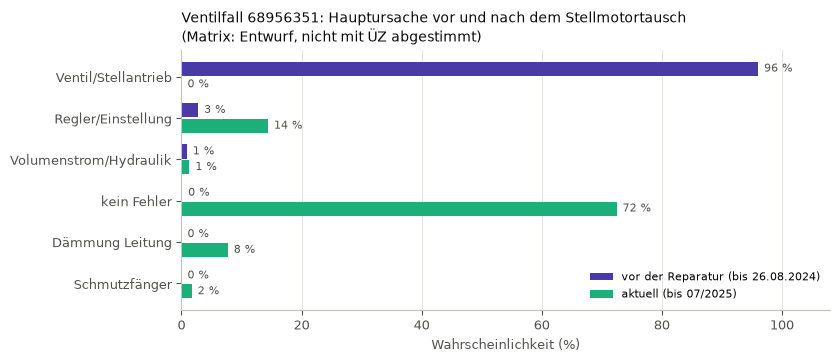

In [14]:
if BEISPIEL in vor["s"].index and BEISPIEL in aktuell["s"].index:
    zeigen = beispiel_post[(beispiel_post.max(axis=1) >= 0.01)].index[::-1]
    y = np.arange(len(zeigen))
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(zeigen) + 1.2))
    h = 0.38
    ax.barh(y + h / 2, beispiel_post.loc[zeigen, "vorher"] * 100, height=h - 0.04, color=FARBE_VORHER,
            label=f"vor der Reparatur (bis {vor['ende']:%d.%m.%Y})")
    ax.barh(y - h / 2, beispiel_post.loc[zeigen, "aktuell"] * 100, height=h - 0.04, color=FARBE_NACHHER,
            label=f"aktuell (bis {aktuell['ende']:%m/%Y})")
    for yy, (a, b) in zip(y, beispiel_post.loc[zeigen].to_numpy()):
        ax.text(a * 100 + 1, yy + h / 2, pz(a), va="center", fontsize=8, color=TINTE_LEISE)
        ax.text(b * 100 + 1, yy - h / 2, pz(b), va="center", fontsize=8, color=TINTE_LEISE)
    ax.set_yticks(y, zeigen, fontsize=9)
    ax.set_xlim(0, 108)
    ax.set_xlabel("Wahrscheinlichkeit (%)", fontsize=9, color=TINTE_LEISE)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    stil(ax)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Ventilfall 68956351: Hauptursache vor und nach dem Stellmotortausch\n({MATRIX_STAND})",
                 loc="left", fontsize=10, color=TINTE)
    fig.tight_layout()
    plt.show()

**Wie man das Bild liest**
- je Klasse zwei Balken: violett vor der Reparatur, türkis aktuell; Klassen unter 1 % in beiden Fenstern fehlen
- gewünscht: violett lang bei Ventil/Stellantrieb, türkis lang bei „kein Fehler“

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 9 · Diagnose aller Stationen (Fenster bis zum Datenende)

- je Station die Ausgabe aus Abschnitt 7, **sortiert nach Datenbeleg**: oben die Stationen, bei denen die Zeitreihen
  am deutlichsten auf einen Fehler zeigen. Das ist die **Prüfreihenfolge**, und sie hängt nicht am Vorwissen
- die Prozentangaben rechnen mit dem Vorwissen der Flotte (`ANTEIL_GESUND_FLOTTE`, Abschnitt 4)
- zum Schluss: Wie viele Stationen gelten als auffällig, wenn der Anteil gesunder Stationen 30 %, 50 % oder 70 % ist?
- die Tabelle zeigt Zählernummern (oder mit `ZAEHLER_ANONYM = True` laufende Kennungen). Vor einem Commit mit
  gespeicherten Ausgaben auf `True` stellen oder die Ausgaben leeren

In [15]:
stand()
POST_AKT = nachher(S_AKT, LOG_PRIOR_FLOTTE)
DIAG = diagnose(S_AKT, POST_AKT)

reihenfolge = ["HAST prüfen", "erst Daten prüfen", "erst Nutzung prüfen", "unauffällig", "zu wenig Daten"]
display(DIAG["Hinweis"].value_counts().reindex(reihenfolge, fill_value=0).to_frame("Stationen").T)
genug = DIAG[DIAG["Hinweis"] != "zu wenig Daten"]
display(pd.crosstab(genug["Hauptursache"], genug["Hinweis"]).reindex(columns=reihenfolge[:4], fill_value=0))
print(f"Stationen mit Hauptursache ueber 90 %: {int((genug['P(Haupt)'] > 0.9).sum())} von {len(genug)}; "
      f"Median der hoechsten Wahrscheinlichkeit: {pz(genug['P(Haupt)'].median())}")

liste = (DIAG.assign(_daten=DIAG["Hinweis"] == "zu wenig Daten")
         .sort_values(["_daten", "Datenbeleg"], ascending=[True, False]))
display(liste.drop(columns="_daten").style.format({"P(kein Fehler)": pz, "P(Haupt)": pz, "Datenbeleg": faktor})
        .hide(axis="index"))

# Wie stark haengt "auffaellig" am Anteil gesunder Stationen? (Datenbeleg und Reihenfolge bleiben gleich)
empfindlich = {}
for anteil in (0.3, 0.5, 0.7):
    p = np.exp(LOG_PRIOR)
    f = p.drop(KEIN_FEHLER)
    lp = np.log(pd.concat([f / f.sum() * (1 - anteil), pd.Series({KEIN_FEHLER: anteil})]).reindex(KLASSEN))
    post = nachher(S_AKT.loc[genug.index], lp)
    empfindlich[pz(anteil)] = {"auffällig (P(kein Fehler) < 50 %)": int((post[KEIN_FEHLER] < AUFFAELLIG_SCHWELLE).sum()),
                               "Hauptursache = Datenbeleg-Fehler": int((post.idxmax(axis=1)
                                                                       == DIAG.loc[genug.index, "Beleg für"]).sum())}
print(f"Anteil gesunder Stationen im Vorwissen (von {len(genug)} Stationen mit genug Daten):")
display(pd.DataFrame(empfindlich))
print("Datenbeleg je Station (mindestens 6 Symptome): "
      + ", ".join(f"{name} {int(maske.sum())}" for name, maske in [
          ("unter x1", genug["Datenbeleg"] < 1), ("x1 bis x10", genug["Datenbeleg"].between(1, 10, inclusive="left")),
          ("x10 bis x100", genug["Datenbeleg"].between(10, 100, inclusive="left")),
          ("ab x100", genug["Datenbeleg"] >= 100)]))

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

Hinweis,HAST prüfen,erst Daten prüfen,erst Nutzung prüfen,unauffällig,zu wenig Daten
Stationen,21,0,0,62,4


Hinweis,HAST prüfen,erst Daten prüfen,erst Nutzung prüfen,unauffällig
Hauptursache,,,,
Regler/Einstellung,3,0,0,0
Ventil/Stellantrieb,14,0,0,0
Volumenstrom/Hydraulik,2,0,0,0
kein Fehler,2,0,0,62


Stationen mit Hauptursache ueber 90 %: 4 von 83; Median der hoechsten Wahrscheinlichkeit: 66 %


station,Symptome,ja,P(kein Fehler),Hauptursache,P(Haupt),Ausgabe,Hinweis,Datenbeleg,Beleg für,Erklärung
68956360,12,"AB, WA, KF, SN, RW, NA",0 %,Ventil/Stellantrieb,96 %,Ventil/Stellantrieb 96 %,HAST prüfen,×5.393,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Kennlinie flach ja (×4,0)"
72167793,12,"AB, WA, KF, SN, RW, NA",0 %,Ventil/Stellantrieb,96 %,Ventil/Stellantrieb 96 %,HAST prüfen,×5.393,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Kennlinie flach ja (×4,0)"
80912173,11,"AB, WA, KF, SN, RW, NA",0 %,Ventil/Stellantrieb,96 %,Ventil/Stellantrieb 96 %,HAST prüfen,×4.825,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Kennlinie flach ja (×4,0)"
80912182,11,"AB, WA, KF, SN, RW, NA",0 %,Ventil/Stellantrieb,96 %,Ventil/Stellantrieb 96 %,HAST prüfen,×4.825,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Kennlinie flach ja (×4,0)"
81050517,10,"AB, KF, SN, RW, NA",1 %,Ventil/Stellantrieb,90 %,"Ventil/Stellantrieb 90 %, Regler/Einstellung 7 %",HAST prüfen,×804,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Kennlinie flach ja (×4,0); Sommer nachts Durchfluss ja (×4,0)"
80912198,12,"AB, WA, SN, RW, NA",1 %,Ventil/Stellantrieb,75 %,"Ventil/Stellantrieb 75 %, Regler/Einstellung 17 %, Volumenstrom/Hydraulik 5 %",HAST prüfen,×634,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Sommer nachts Durchfluss ja (×4,0)"
68956372,11,"AB, WA, SN, RW, NA, SA",1 %,Ventil/Stellantrieb,75 %,"Ventil/Stellantrieb 75 %, Regler/Einstellung 17 %, Volumenstrom/Hydraulik 5 %",HAST prüfen,×568,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Sommer nachts Durchfluss ja (×4,0)"
80956410,12,"AB, WA, SN, RW, NA, DE",3 %,Ventil/Stellantrieb,73 %,"Ventil/Stellantrieb 73 %, Regler/Einstellung 17 %, Volumenstrom/Hydraulik 5 %",HAST prüfen,×189,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Sommer nachts Durchfluss ja (×4,0)"
72135480,12,"AB, WA, SN, RW",3 %,Ventil/Stellantrieb,51 %,"Ventil/Stellantrieb 51 %, Volumenstrom/Hydraulik 31 %, Regler/Einstellung 12 %",HAST prüfen,×181,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Viel Wasser je kW ja (×6,0); Sommer nachts Durchfluss ja (×4,0)"
81062289,10,"AB, KF, RW, NA",7 %,Ventil/Stellantrieb,70 %,"Ventil/Stellantrieb 70 %, Regler/Einstellung 20 %, kein Fehler 7 %",HAST prüfen,×95,Ventil/Stellantrieb,"für Ventil/Stellantrieb spricht: Abkühlung schlecht ja (×6,0); Kennlinie flach ja (×4,0); Rücklauf dauerhaft warm ja (×3,0)"


Anteil gesunder Stationen im Vorwissen (von 83 Stationen mit genug Daten):


,30 %,50 %,70 %
auffällig (P(kein Fehler) < 50 %),55,21,19
Hauptursache = Datenbeleg-Fehler,23,18,17


Datenbeleg je Station (mindestens 6 Symptome): unter x1 19, x1 bis x10 46, x10 bis x100 9, ab x100 9


**Was macht die Zelle?**
- rechnet für jede Station mit Daten im aktuellen Fenster die Wahrscheinlichkeiten, den Datenbeleg und die
  Ausgabezeile
- erste Tabelle: wie viele Stationen welchen Hinweis bekommen
- zweite Tabelle: Hauptursache gegen Hinweis (nur Stationen mit genug Daten)
- dritte Tabelle: die ganze Liste in Prüfreihenfolge (Datenbeleg absteigend, „zu wenig Daten“ am Ende)
- vierte Tabelle: wie viele Stationen bei 30 %, 50 % und 70 % gesunden Stationen im Vorwissen als auffällig gelten,
  und bei wie vielen die Hauptursache derselbe Fehler ist, für den der Datenbeleg spricht
- letzte Zeile: wie viele Stationen keinen (unter ×1), kaum (×1 bis ×10), deutlichen (×10 bis ×100) oder sehr
  deutlichen Beleg (ab ×100) für einen Fehler zeigen

**Wie man die Liste liest**
- `ja`: welche Symptome die Station zeigt (Kürzel wie Abschnitt 5)
- `Datenbeleg` und `Beleg für`: was die Zeitreihe allein sagt. Unter ×1 passen die Daten besser zu „kein Fehler“
  als zu jedem Fehler
- `Ausgabe` und `Erklärung` zusammen lesen: Wie sicher ist die Hauptursache, und welche Symptome tragen sie?
- Sehr hohe Werte (über 90 %) bei mehreren zusammenhängenden Symptomen sind vermutlich zu sicher (Abschnitt 6)
- „HAST prüfen“ mit Hauptursache „kein Fehler“ heißt: Mehrere Fehler sind zusammen wahrscheinlicher als
  „kein Fehler“, aber keiner sticht heraus

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

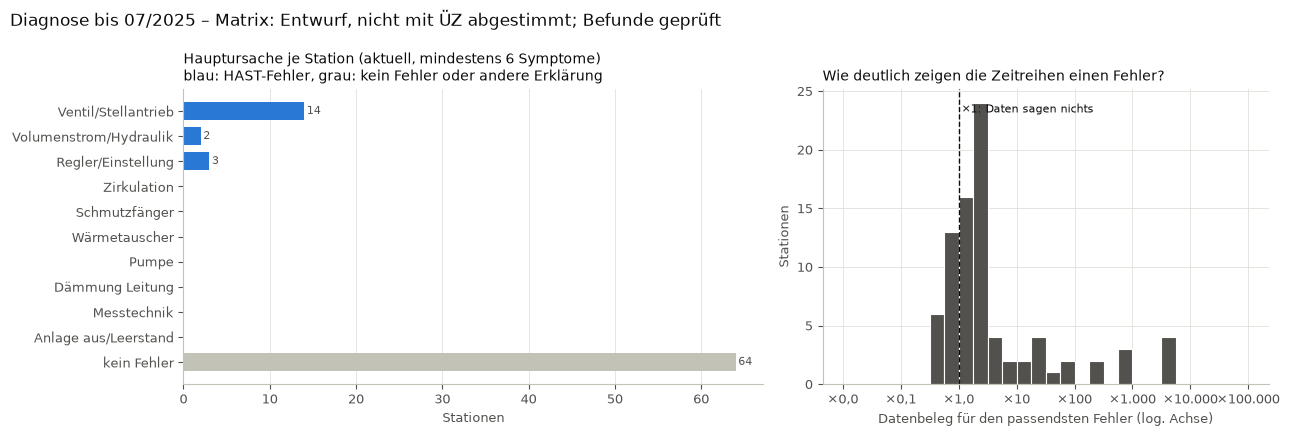

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
zaehlung = genug["Hauptursache"].value_counts().reindex(KLASSEN, fill_value=0).iloc[::-1]
farben = [FARBE_HAUPT if k not in (KEIN_FEHLER, *ANDERE_ERKLAERUNG) else ACHSE for k in zaehlung.index]
ax.barh(zaehlung.index, zaehlung.to_numpy(), color=farben, height=0.7)
for yy, n in enumerate(zaehlung.to_numpy()):
    if n:
        ax.text(n + 0.3, yy, str(n), va="center", fontsize=8, color=TINTE_LEISE)
ax.set_xlabel("Stationen", fontsize=9, color=TINTE_LEISE)
ax.set_title("Hauptursache je Station (aktuell, mindestens 6 Symptome)\nblau: HAST-Fehler, grau: kein Fehler "
             "oder andere Erklärung", loc="left", fontsize=10, color=TINTE)
stil(ax)
ax.grid(axis="y", visible=False)

ax = axes[1]
log_beleg = np.log10(genug["Datenbeleg"].clip(1e-2, 1e5))
ax.hist(log_beleg, bins=np.arange(-2, 5.25, 0.25), color=TINTE_LEISE, edgecolor="white", linewidth=0.8)
ax.axvline(0, color=TINTE, linestyle="--", linewidth=1)
ax.text(0.05, ax.get_ylim()[1] * 0.92, "×1: Daten sagen nichts", fontsize=8, color=TINTE)
stufen = [-2, -1, 0, 1, 2, 3, 4, 5]
ax.set_xticks(stufen, [faktor(10.0 ** s) for s in stufen])
ax.set_xlabel("Datenbeleg für den passendsten Fehler (log. Achse)", fontsize=9, color=TINTE_LEISE)
ax.set_ylabel("Stationen", fontsize=9, color=TINTE_LEISE)
ax.set_title("Wie deutlich zeigen die Zeitreihen einen Fehler?", loc="left", fontsize=10, color=TINTE)
stil(ax)
fig.suptitle(f"Diagnose bis {DATENENDE:%m/%Y} – {MATRIX_STAND}; Befunde {LABEL_STAND}", x=0.01, ha="left",
             color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- links: wie oft jede Klasse die Hauptursache ist. Erwartet ist viel „kein Fehler“ und einzelne Fehler; steht fast
  alles bei einer Klasse, ist das eher ein Zeichen für eine zu grobe Matrix als für eine kranke Flotte
- rechts: Verteilung des Datenbelegs, ganz ohne Vorwissen. Links der gestrichelten Linie passen die Daten besser zu
  „kein Fehler“, rechts zu einem Fehler. Ein klarer Fehler wie das offene Ventil liegt bei ×1.000 und mehr
- Liegen fast alle Stationen nahe ×1, sagen die Symptome über die meisten Stationen wenig. Dann entscheidet bei
  ihnen das Vorwissen, und mehr Information gibt es nur über bessere Symptome

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 10 · Prüfung gegen die Begehungen

**Die Frage:** Passt die Diagnose aus dem Jahr **vor** der Begehung zu dem, was vor Ort gefunden wurde?

**So wird geprüft**
- je Begehung mit Befund, Datum und Messdaten: Fenster von einem Jahr, Ende 14 Tage vor dem Termin
- **Vorwissen ohne die eigene Station** (Leave-one-out): Die Häufigkeiten werden aus allen anderen Stationen
  gezählt. Sonst stünde der Befund der Station schon in ihrem eigenen Vorwissen
- die Matrix stammt nicht aus den Begehungen, sie wird hier nicht angepasst
- **Treffer:** Die wahrscheinlichste Klasse ist einer der Befunde der Begehung (bei zwei Befunden zählt beides)

**Drei Vergleichsmaße**

| Maß | Bedeutung |
|---|---|
| Top-1-Treffer | Anteil der Begehungen, bei denen die wahrscheinlichste Klasse ein Befund war |
| Top-3-Treffer | dasselbe für die drei wahrscheinlichsten Klassen |
| mittlere P(Befund) | Wahrscheinlichkeit, die das Modell den tatsächlichen Befunden gab, gemittelt. Feiner als Treffer/kein Treffer |

**Zwei Messlatten**
- **nur Vorwissen:** jede Station bekommt einfach die Häufigkeiten. Ein Modell, das das nicht schlägt, hat aus den
  Symptomen nichts gelernt
- **Zufall (Permutation):** Die Befunde werden 5000-mal zufällig auf die Begehungen verteilt, die Diagnosen bleiben.
  Das prüft, ob die Diagnose zur **richtigen Station** passt und nicht nur im Mittel stimmt. p = Anteil der
  Mischungen, die mindestens so gut sind wie die echte Zuordnung

**Zusätzlich: Findet das Modell die Stationen mit Befund?** Vergleich von 1 − P(kein Fehler) zwischen Begehungen mit
einem HAST-Befund und Begehungen mit „kein Befund“ (AUC: 0,5 = Zufall, 1 = perfekt getrennt).

In [17]:
stand()
zeilen_s, zeilen_lp, grund = [], [], {}
for _, f in faelle.iterrows():
    if f["ausschluss"]:
        grund[f["nr"]] = f["ausschluss"]
        continue
    if not f["hat_daten"]:
        grund[f["nr"]] = "keine Messdaten"
        continue
    if pd.isna(f["datum"]):
        grund[f["nr"]] = "ohne Datum"
        continue
    fen = symptome_im_fenster(f["datum"] - pd.Timedelta(days=ABSTAND_BEGEHUNG))
    z = int(f["zaehler"])
    if z not in fen["s"].index:
        grund[f["nr"]] = "keine Daten im Fenster"
        continue
    s = fen["s"].loc[z]
    if s.notna().sum() < MIN_SYMPTOME:
        grund[f["nr"]] = "zu wenig Daten"
        continue
    grund[f["nr"]] = "bewertet"
    zeilen_s.append(s.rename(f["nr"]))
    zeilen_lp.append(vorwissen(faelle_vorwissen[faelle_vorwissen["zaehler"] != z])[0].to_numpy())

grund = pd.Series(grund)
display(grund.value_counts().to_frame("Begehungen").T)
print(f"Pruef-Fenster gerechnet: {len(FENSTER) - 1} (eines je Begehungsdatum)")

PRUEF = faelle.set_index("nr").loc[[s.name for s in zeilen_s]]
S_PR = pd.DataFrame(zeilen_s)
LP_PR = np.vstack(zeilen_lp)
POST_PR = nachher(S_PR, LP_PR)
PRIOR_PR = pd.DataFrame(np.exp(LP_PR), index=S_PR.index, columns=KLASSEN)
LAB = pd.DataFrame([[float(k in kl) for k in KLASSEN] for kl in PRUEF["klassen"]], index=S_PR.index,
                   columns=KLASSEN)


def kennzahlen(post, lab):
    """Top-1, Top-3, mittlere P(Befund) und mittlerer log P(Befund) fuer Diagnosen gegen Befunde."""
    p, L = np.asarray(post, dtype=float), np.asarray(lab, dtype=float)
    rang = np.argsort(-p, axis=1)
    top1 = L[np.arange(len(L)), rang[:, 0]] == 1
    top3 = np.take_along_axis(L, rang[:, :3], axis=1).sum(axis=1) > 0
    p_bef = (p * L).sum(axis=1)
    return {"Top-1-Treffer": top1.mean(), "Top-3-Treffer": top3.mean(),
            "mittlere P(Befund)": p_bef.mean(), "mittlerer log P(Befund)": np.log(p_bef).mean()}


rng = np.random.default_rng(SEED)
echt = kennzahlen(POST_PR, LAB)
basis = kennzahlen(PRIOR_PR, LAB)
perm = pd.DataFrame([kennzahlen(POST_PR, LAB.to_numpy()[rng.permutation(len(LAB))])
                     for _ in range(N_PERMUTATIONEN)])
pruef_tab = pd.DataFrame({"Modell": echt, "nur Vorwissen": basis, "Zufall (Mittel)": perm.mean()})
pruef_tab["p (Modell gegen Zufall)"] = [(1 + (perm[m] >= echt[m]).sum()) / (1 + N_PERMUTATIONEN) for m in echt]
print(f"bewertete Begehungen: {len(LAB)} an {PRUEF['zaehler'].nunique()} Stationen "
      f"(geprueft {int((PRUEF['label_quelle'] == 'geprüft').sum())}, "
      f"automatisch {int((PRUEF['label_quelle'] == 'automatisch').sum())})")
display(pruef_tab.style.format({"Modell": "{:.3f}", "nur Vorwissen": "{:.3f}", "Zufall (Mittel)": "{:.3f}",
                                "p (Modell gegen Zufall)": "{:.4f}"}))

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

,bewertet,ohne Datum,keine Messdaten,keine Daten im Fenster,zu wenig Daten
Begehungen,50,6,6,2,1


Pruef-Fenster gerechnet: 29 (eines je Begehungsdatum)
bewertete Begehungen: 50 an 49 Stationen (geprueft 50, automatisch 0)


,Modell,nur Vorwissen,Zufall (Mittel),p (Modell gegen Zufall)
Top-1-Treffer,0.460,0.640,0.401,0.1822
Top-3-Treffer,0.900,0.900,0.834,0.0632
mittlere P(Befund),0.397,0.312,0.311,0.0004
mittlerer log P(Befund),-1.180,-1.305,-1.750,0.0002


**Was macht die Zelle?**
- geht alle Begehungen durch und hält fest, warum eine nicht bewertet wird (erste Tabelle)
- berechnet für jede bewertete Begehung die Symptome im Jahr davor und die Diagnose mit Leave-one-out-Vorwissen
- vergleicht mit „nur Vorwissen“ und mit 5000 zufälligen Zuordnungen

**Wie man die Tabelle liest**
- **Modell über „nur Vorwissen“:** Die Symptome helfen gegenüber dem bloßen Raten nach Häufigkeit
- **Modell über „Zufall“ und p klein:** Die Diagnose passt zur richtigen Station. Bei vier Maßen ist ein einzelnes
  p knapp unter 0,05 nicht belastbar (vier Tests), die Maße hängen aber stark zusammen
- **mittlerer log P(Befund):** bestraft sichere Fehldiagnosen hart. Liegt er unter „nur Vorwissen“, obwohl die
  Treffer besser sind, ist das Modell zu sicher (Abschnitt 6)
- Alles ist **vorläufig**, solange die Befunde automatisch kodiert sind: Die Prüfung misst dann zum Teil die
  Kodierung, nicht das Modell

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

In [18]:
p_bef = (POST_PR * LAB).sum(axis=1)
top1 = POST_PR.idxmax(axis=1)
treffer = pd.Series([LAB.at[i, k] == 1 for i, k in top1.items()], index=top1.index)

nach_quelle = pd.DataFrame({"Begehungen": PRUEF.groupby("label_quelle").size(),
                            "Top-1-Treffer": treffer.groupby(PRUEF["label_quelle"]).mean(),
                            "mittlere P(Befund)": p_bef.groupby(PRUEF["label_quelle"]).mean()})
display(nach_quelle.round(3))

je_klasse = []
for k in KLASSEN:
    hat = LAB[k] == 1
    je_klasse.append({"Klasse": k, "Begehungen mit diesem Befund": int(hat.sum()),
                      "mittl. P(k), mit Befund": POST_PR.loc[hat, k].mean() if hat.any() else np.nan,
                      "mittl. P(k), übrige": POST_PR.loc[~hat, k].mean(),
                      "Vorwissen P(k)": PRIOR_PR[k].mean(),
                      "Top-1 = k": int((top1 == k).sum()), "davon Treffer": int(((top1 == k) & hat).sum())})
display(pd.DataFrame(je_klasse).set_index("Klasse").style.format(
    {"mittl. P(k), mit Befund": pz, "mittl. P(k), übrige": pz, "Vorwissen P(k)": pz}))

# Findet das Modell die Begehungen mit HAST-Befund?
hast = PRUEF["klassen"].map(lambda kl: any(k not in (KEIN_FEHLER, *ANDERE_ERKLAERUNG) for k in kl))
kein = PRUEF["klassen"].map(lambda kl: kl == [KEIN_FEHLER])
auff = 1 - POST_PR[KEIN_FEHLER]
if hast.sum() >= 3 and kein.sum() >= 3:
    teil = hast | kein
    auc = roc_auc_score(hast[teil].astype(int), auff[teil])
    mw = stats.mannwhitneyu(auff[hast], auff[kein], alternative="greater")
    print(f"Auffaelligkeit: HAST-Befund n = {int(hast.sum())}, kein Befund n = {int(kein.sum())}; "
          f"Median 1 - P(kein Fehler) {pz(auff[hast].median())} gegen {pz(auff[kein].median())}; "
          f"AUC {auc:.2f}, Mann-Whitney einseitig p = {mw.pvalue:.3f}")
    beleg_pr = np.log(datenbeleg(S_PR)["beleg"])
    auc_b = roc_auc_score(hast[teil].astype(int), beleg_pr[teil])
    mw_b = stats.mannwhitneyu(beleg_pr[hast], beleg_pr[kein], alternative="greater")
    print(f"Datenbeleg (ohne Vorwissen): Median {faktor(np.exp(beleg_pr[hast].median()))} gegen "
          f"{faktor(np.exp(beleg_pr[kein].median()))}; AUC {auc_b:.2f}, Mann-Whitney einseitig p = {mw_b.pvalue:.3f}")
else:
    print("Auffaelligkeit: zu wenige Begehungen in einer der Gruppen")

if BEISPIEL in set(PRUEF["zaehler"]):
    i = PRUEF.index[PRUEF["zaehler"] == BEISPIEL][0]
    rang = int((POST_PR["Ventil/Stellantrieb"] > POST_PR.at[i, "Ventil/Stellantrieb"]).sum()) + 1
    print(f"Ventilfall: Hauptursache {top1[i]} ({pz(POST_PR.loc[i].max())}); nach P(Ventil/Stellantrieb) "
          f"Rang {rang} von {len(POST_PR)} bewerteten Begehungen")

verwechslung = pd.crosstab(
    pd.Series([k for kl in PRUEF["klassen"] for k in kl], name="Befund"),
    pd.Series([top1[i] for i, kl in zip(PRUEF.index, PRUEF["klassen"]) for _ in kl], name="Hauptursache Modell"))
display(verwechslung)

,Begehungen,Top-1-Treffer,mittlere P(Befund)
label_quelle,,,
geprüft,50,0.46,0.397


,Begehungen mit diesem Befund,"mittl. P(k), mit Befund","mittl. P(k), übrige",Vorwissen P(k),Top-1 = k,davon Treffer
Klasse,,,,,,
Ventil/Stellantrieb,10,40 %,1 %,9 %,5,5
Volumenstrom/Hydraulik,7,8 %,8 %,9 %,1,0
Regler/Einstellung,32,35 %,27 %,36 %,24,16
Zirkulation,4,2 %,3 %,5 %,0,0
Schmutzfänger,3,3 %,4 %,6 %,0,0
Wärmetauscher,0,–,2 %,1 %,0,0
Pumpe,0,–,1 %,1 %,0,0
Dämmung Leitung,9,20 %,16 %,11 %,12,2
Messtechnik,2,0 %,1 %,3 %,0,0


Auffaelligkeit: HAST-Befund n = 41, kein Befund n = 9; Median 1 - P(kein Fehler) 73 % gegen 75 %; AUC 0.47, Mann-Whitney einseitig p = 0.600
Datenbeleg (ohne Vorwissen): Median ×2,6 gegen ×2,6; AUC 0.55, Mann-Whitney einseitig p = 0.338
Ventilfall: Hauptursache Ventil/Stellantrieb (96 %); nach P(Ventil/Stellantrieb) Rang 3 von 50 bewerteten Begehungen


Hauptursache Modell,Dämmung Leitung,Regler/Einstellung,Ventil/Stellantrieb,Volumenstrom/Hydraulik,kein Fehler
Befund,,,,,
Anlage aus/Leerstand,0,1,0,0,0
Dämmung Leitung,2,4,0,0,3
Messtechnik,1,1,0,0,0
Regler/Einstellung,5,16,3,1,7
Schmutzfänger,1,0,1,0,1
Ventil/Stellantrieb,0,3,5,1,1
Volumenstrom/Hydraulik,1,5,1,0,0
Zirkulation,0,3,0,0,1
kein Fehler,4,5,0,0,0


**Was macht die Zelle?**
- erste Tabelle: Treffer getrennt nach Herkunft des Befunds. Sobald du Notizen prüfst, sieht man hier, ob das Modell
  zu den geprüften Befunden besser passt als zu den automatischen
- zweite Tabelle je Klasse: Bekommen Begehungen **mit** diesem Befund eine höhere Wahrscheinlichkeit für ihn als
  die übrigen? Das ist die eigentliche Frage je Fehlerart. „Top-1 = k“ zählt, wie oft das Modell k vorne sieht
- Auffälligkeit: Trennt 1 − P(kein Fehler) die Begehungen mit HAST-Befund von denen ohne? Dasselbe noch einmal mit
  dem Datenbeleg, also nur aus den Zeitreihen
- Ventilfall: welchen Rang er nach P(Ventil/Stellantrieb) unter allen bewerteten Begehungen hat
- letzte Tabelle: Befund (Zeile) gegen Hauptursache des Modells (Spalte). Die Diagonale sind Treffer

**Worauf achten**
- Bei 1 bis 5 Begehungen je Klasse sind die Werte je Klasse nur Hinweise
- „Regler/Einstellung“ ist in der automatischen Kodierung häufig, meint dort aber oft eine **Maßnahme** (Heizzeiten
  geändert), keinen Befund. Diese Zeile wird sich durch die Prüfliste am stärksten ändern

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

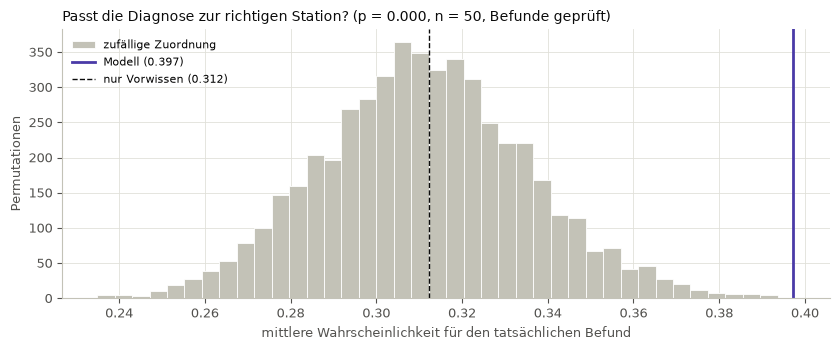

In [19]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
m = "mittlere P(Befund)"
ax.hist(perm[m], bins=40, color=ACHSE, edgecolor="white", linewidth=0.6, label="zufällige Zuordnung")
ax.axvline(echt[m], color=FARBE_VORHER, linewidth=2, label=f"Modell ({echt[m]:.3f})")
ax.axvline(basis[m], color=TINTE, linestyle="--", linewidth=1, label=f"nur Vorwissen ({basis[m]:.3f})")
ax.set_xlabel("mittlere Wahrscheinlichkeit für den tatsächlichen Befund", fontsize=9, color=TINTE_LEISE)
ax.set_ylabel("Permutationen", fontsize=9, color=TINTE_LEISE)
ax.legend(frameon=False, fontsize=8)
ax.set_title(f"Passt die Diagnose zur richtigen Station? (p = {pruef_tab.at[m, 'p (Modell gegen Zufall)']:.3f}, "
             f"n = {len(LAB)}, Befunde {LABEL_STAND})", loc="left", fontsize=10, color=TINTE)
stil(ax)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- graue Säulen: mittlere P(Befund), wenn die Befunde zufällig auf die Begehungen verteilt werden
- violette Linie: die echte Zuordnung. Liegt sie weit rechts von den Säulen, passt die Diagnose zur Station
- gestrichelt: nur Vorwissen. Liegt das Modell links davon, schadet es im Mittel (zu sichere Fehldiagnosen)

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 11 · Zweite Sicht: jeder Fehler gegen „kein Fehler“

- Die Hauptrechnung zwingt die Klassen in eine Summe von 100 %. Hat eine Station **zwei** Fehler, teilen sie sich
  die Wahrscheinlichkeit, und jeder sieht kleiner aus.
- Hier wird jeder Fehler **für sich** gegen „kein Fehler“ gestellt:
  P(F gegen kein Fehler) = P(F) · P(S | F) / (P(F) · P(S | F) + P(kein Fehler) · P(S | kein Fehler)).
- Die Werte summieren sich **nicht** auf 100 %. Sie sagen je Fehler: Passen die Daten eher zu diesem Fehler oder
  eher zu einer gesunden Station?

In [20]:
def gegen_kein_fehler(S, log_prior=None):
    """Je Fehler: Wahrscheinlichkeit 'F' im Zweikampf gegen 'kein Fehler' (summiert nicht auf 1)."""
    lp = LOG_PRIOR.to_numpy() if log_prior is None else np.asarray(log_prior, dtype=float)
    z = log_likelihood(S) + lp
    k0 = KLASSEN.index(KEIN_FEHLER)
    d = z - z[:, [k0]]
    return pd.DataFrame(1 / (1 + np.exp(-d)), index=S.index, columns=KLASSEN).drop(columns=KEIN_FEHLER)


stand()
ZWEI_AKT = gegen_kein_fehler(S_AKT, LOG_PRIOR_FLOTTE).loc[genug.index]
ZWEI_PR = gegen_kein_fehler(S_PR, LP_PR)
zeilen = []
for k in ZWEI_AKT.columns:
    hat, ohne = LAB[k] == 1, kein
    auc_k = (roc_auc_score(np.r_[np.ones(hat.sum()), np.zeros(ohne.sum())],
                           np.r_[ZWEI_PR.loc[hat, k], ZWEI_PR.loc[ohne, k]])
             if hat.sum() >= 3 and ohne.sum() >= 3 else np.nan)
    zeilen.append({"Fehler": k, "aktuell: Stationen über 50 %": int((ZWEI_AKT[k] > 0.5).sum()),
                   "aktuell: Median": ZWEI_AKT[k].median(),
                   "Prüfung: Begehungen mit Befund": int(hat.sum()),
                   "Prüfung: AUC gegen 'kein Befund'": auc_k})
display(pd.DataFrame(zeilen).set_index("Fehler").style.format({"aktuell: Median": pz,
                                                               "Prüfung: AUC gegen 'kein Befund'": "{:.2f}"}))
mehrere = (ZWEI_AKT > 0.5).sum(axis=1)
print(f"aktuell: Stationen mit mindestens einem Fehler ueber 50 %: {int((mehrere >= 1).sum())} von {len(ZWEI_AKT)}, "
      f"mit zwei oder mehr: {int((mehrere >= 2).sum())}")

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

,aktuell: Stationen über 50 %,aktuell: Median,Prüfung: Begehungen mit Befund,Prüfung: AUC gegen 'kein Befund'
Fehler,,,,
Ventil/Stellantrieb,15,0 %,10,0.92
Volumenstrom/Hydraulik,11,2 %,7,0.65
Regler/Einstellung,18,18 %,32,0.57
Zirkulation,4,1 %,4,0.42
Schmutzfänger,0,1 %,3,0.19
Wärmetauscher,0,1 %,0,nan
Pumpe,0,1 %,0,nan
Dämmung Leitung,0,5 %,9,0.31
Messtechnik,0,0 %,2,nan


aktuell: Stationen mit mindestens einem Fehler ueber 50 %: 19 von 83, mit zwei oder mehr: 15


**Was macht die Zelle?**
- rechnet je Station und Fehler den Zweikampf „F gegen kein Fehler“, für das aktuelle Fenster (Vorwissen der
  Flotte) und für die Prüf-Fenster (Vorwissen der Begehungen)
- aktuell: Wie viele Stationen liegen bei einem Fehler über 50 %? Wie viele bei mehreren gleichzeitig?
- Prüfung: Trennt dieser Wert die Begehungen mit diesem Befund von denen mit „kein Befund“? AUC nur ab je 3
  Begehungen, sonst leer

**Worauf achten**
- Fehler mit ähnlichen Zeilen in der Matrix (Ventil, Volumenstrom, Wärmetauscher) gewinnen ihren Zweikampf oft
  gemeinsam. Hier sieht man, welche Fehler das Modell gar nicht auseinanderhalten kann
- Zwei Fehler über 50 % sind mit den Zählerdaten oft nicht zu trennen. Was es wirklich ist, klärt dann der Termin vor Ort

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 12 · Wie stark hängt das Ergebnis am Entwurf der Matrix?

- Die Matrix ist ein Entwurf. Die Frage hier: Ändert sich die Diagnose, wenn jedes Feld um **eine Stufe** daneben
  liegt?
- In jeder von 200 Ziehungen wird jedes Feld zufällig eine Stufe hoch, eine Stufe runter oder gar nicht verschoben
  (je ein Drittel; „unbekannt“ bleibt „unbekannt“; über „fast immer“ und unter „nie“ geht es nicht hinaus)
  **[Annahme: „eine Stufe daneben“ ist die typische Unsicherheit eines Entwurfs]**.
- Gemessen wird je Station mit genug Daten: Wie oft bleibt die Hauptursache gleich, wie oft bleibt „auffällig“
  gleich? Dazu die Prüfmaße aus Abschnitt 10 über alle Ziehungen.

In [21]:
stand()
STUFE_INDEX = {s: i for i, s in enumerate(STUFEN_GEORDNET)}
rng = np.random.default_rng(SEED)
S_GENUG = S_AKT.loc[genug.index]
basis_haupt = POST_AKT.loc[genug.index].idxmax(axis=1)
basis_auff = POST_AKT.loc[genug.index, KEIN_FEHLER] < AUFFAELLIG_SCHWELLE
gleich_haupt = pd.Series(0.0, index=genug.index)
gleich_auff = pd.Series(0.0, index=genug.index)
pruef_wackeln = []
rang_beleg = []
basis_beleg = datenbeleg(S_GENUG)["beleg"]
stufen_alt = STUFE_FINAL.to_numpy(dtype=object)
bekannt = stufen_alt != "unbekannt"
index_alt = np.array([STUFE_INDEX[s] for s in stufen_alt[bekannt]])
for _ in range(N_WACKELN):
    werte = stufen_alt.copy()
    pos = np.clip(index_alt + rng.integers(-1, 2, size=len(index_alt)), 0, len(STUFEN_GEORDNET) - 1)
    werte[bekannt] = np.array(STUFEN_GEORDNET, dtype=object)[pos]
    P_w = matrix_aus_stufen(pd.Series(werte, index=STUFE_FINAL.index))
    post = nachher(S_GENUG, LOG_PRIOR_FLOTTE, P_mat=P_w)
    rang_beleg.append(stats.spearmanr(datenbeleg(S_GENUG, P_w)["beleg"], basis_beleg).statistic)
    gleich_haupt += (post.idxmax(axis=1) == basis_haupt)
    gleich_auff += ((post[KEIN_FEHLER] < AUFFAELLIG_SCHWELLE) == basis_auff)
    pruef_wackeln.append(kennzahlen(nachher(S_PR, LP_PR, P_w), LAB))
gleich_haupt /= N_WACKELN
gleich_auff /= N_WACKELN
pruef_wackeln = pd.DataFrame(pruef_wackeln)

print(f"Stationen mit genug Daten: {len(genug)}")
print(f"Hauptursache bleibt gleich: Median {pz(gleich_haupt.median())} der Ziehungen; "
      f"in mindestens 80 % der Ziehungen bei {int((gleich_haupt >= 0.8).sum())} Stationen")
print(f"'auffaellig' bleibt gleich: Median {pz(gleich_auff.median())}; "
      f"in mindestens 80 % bei {int((gleich_auff >= 0.8).sum())} Stationen")
print(f"Reihenfolge nach Datenbeleg (Spearman zur Entwurfsmatrix): Median {zahl(np.median(rang_beleg), 2)}, "
      f"5-%-Quantil {zahl(np.quantile(rang_beleg, 0.05), 2)}")
display(pd.DataFrame({"Hinweis": genug["Hinweis"], "Hauptursache stabil": gleich_haupt}).groupby("Hinweis")
        ["Hauptursache stabil"].agg(["size", "median"]).rename(columns={"size": "Stationen", "median": "Median"})
        .style.format({"Median": pz}))
wackel_tab = pruef_wackeln.quantile([0.05, 0.5, 0.95]).T
wackel_tab.columns = ["5 %", "Median", "95 %"]
wackel_tab["Entwurf"] = pd.Series(echt)
wackel_tab["Zufall (Mittel)"] = perm.mean()
display(wackel_tab.round(3))

> **Matrix: Entwurf, nicht mit ÜZ abgestimmt** (0 von 132 Feldern von ÜZ geprüft)  
> **Befunde geprüft:** 57 von 57 Notizen geprüft.

Stationen mit genug Daten: 83
Hauptursache bleibt gleich: Median 84 % der Ziehungen; in mindestens 80 % der Ziehungen bei 51 Stationen
'auffaellig' bleibt gleich: Median 78 %; in mindestens 80 % bei 33 Stationen
Reihenfolge nach Datenbeleg (Spearman zur Entwurfsmatrix): Median 0,61, 5-%-Quantil 0,26


,Stationen,Median
Hinweis,,
HAST prüfen,21,64 %
unauffällig,62,86 %


,5 %,Median,95 %,Entwurf,Zufall (Mittel)
Top-1-Treffer,0.280,0.380,0.501,0.460,0.401
Top-3-Treffer,0.680,0.800,0.920,0.900,0.834
mittlere P(Befund),0.291,0.348,0.424,0.397,0.311
mittlerer log P(Befund),-1.999,-1.567,-1.224,-1.180,-1.750


**Was macht die Zelle?**
- verschiebt 200-mal alle Felder der Matrix zufällig um höchstens eine Stufe und rechnet alles neu
- zählt je Station, in wie vielen Ziehungen Hauptursache und „auffällig“ gleich bleiben
- misst, wie ähnlich die Prüfreihenfolge nach Datenbeleg bleibt (Spearman, 1 = gleiche Reihenfolge)
- zeigt, wie stark die Prüfmaße aus Abschnitt 10 dabei schwanken (5 %, Median, 95 % der Ziehungen)

**Wie man das liest**
- Eine Hauptursache, die in 80 % der Ziehungen gleich bleibt, hängt nicht an einzelnen Feldern. Bleibt sie nur in
  40 % gleich, entscheidet der Entwurf, nicht die Daten
- Liegen die Prüfmaße auch bei 5 % noch über „Zufall“, trägt die **Struktur** der Matrix (welche Felder hoch, welche
  niedrig) und nicht die genaue Stufe
- Stationen mit instabiler Hauptursache sind die besten Kandidaten, um mit Frank genau die betroffenen Felder zu
  besprechen

**Ergebnis** *(nach dem Lauf ausfüllen)*
- …

## 13 · Ergebnis speichern (optional)

- nur mit `SPEICHERN = True` (Abschnitt 1); Ziel ist `outputs/31_bayes_diagnose/`, **nie** `data/`
- `diagnose_aktuell.csv`: eine Zeile je Station (Ausgabe, Hinweis, Erklärung, Wahrscheinlichkeiten aller Klassen)
- `pruefung.csv`: eine Zeile je bewerteter Begehung (Nr., Befunde, Herkunft, Wahrscheinlichkeiten)

In [22]:
if SPEICHERN:
    if "data" in AUSGABE_DIR.relative_to(ROOT).parts:
        raise ValueError("AUSGABE_DIR darf nicht unter data/ liegen")
    AUSGABE_DIR.mkdir(parents=True, exist_ok=True)
    stand_spalten = {"matrix_stand": MATRIX_STAND, "matrix_felder_uez": N_FRANK,
                     "befunde_geprueft": N_GEPRUEFT, "befunde_notizen": N_NOTIZEN}
    DIAG.join(POST_AKT.add_prefix("P_")).assign(**stand_spalten).to_csv(AUSGABE_DIR / "diagnose_aktuell.csv")
    (PRUEF[["datum", "zaehler", "label_quelle", "klassen"]].join(POST_PR.add_prefix("P_"))
     .assign(**stand_spalten).to_csv(AUSGABE_DIR / "pruefung.csv"))
    print(f"gespeichert unter {AUSGABE_DIR}")
else:
    print("SPEICHERN = False: nichts geschrieben")

SPEICHERN = False: nichts geschrieben


**Was macht die Zelle?**
- schreibt die beiden Tabellen nur, wenn `SPEICHERN = True`, und bricht ab, falls der Zielordner unter `data/` läge
- jede Zeile trägt den Stand der beiden Handtabellen mit, damit später klar ist, mit welcher Matrix gerechnet wurde

**Ergebnis:** beim ersten Lauf nichts gespeichert.

## 14 · Einordnung

*Stand: Lauf am 20.10.2026 mit Sebs Prüfliste (alle 57 Notizen geprüft, „Frank fragen“ nicht berücksichtigt),
Matrix im Entwurf (0 von 132 Feldern mit ÜZ abgestimmt), Vorwissen der Flotte 50 % gesund **[Annahme]**, Fenster
„aktuell“ bis zum Datenende 10.07.2025. Nach Änderungen an Prüfliste oder Matrix neu lesen.*

**Was funktioniert**
- **Ventil/Stellantrieb hat als einzige Fehlerart eine klare Spur.**
  - Begehungen mit Ventilbefund bekamen im Mittel 40 % dafür, die übrigen 1 % (n = 10).
  - Alle 5 Begehungen, bei denen das Modell das Ventil vorne sah, hatten einen Ventilbefund.
  - Im Zweikampf gegen „kein Befund“ AUC 0,92.
  - Ventilfall: Datenbeleg ×1.600 vor der Reparatur, ×0,8 danach (unauffällig).
- **Flotte:** 21 von 83 Stationen mit genug Daten sind „HAST prüfen“, davon 13 mit Hauptursache Ventil. Einen
  deutlichen Datenbeleg (ab ×10) zeigen 17 Stationen, 10 davon sehr deutlich (ab ×100).
- **Die Diagnose passt besser zur richtigen Station als bei zufälliger Zuordnung:** mittlere P(Befund) 0,40 gegen
  0,31 (p = 0,0004). Der Log-Score ist besser als nur Vorwissen (−1,18 gegen −1,31).

**Was schwach ist**
- **Die Zeitreihen sagen über die meisten Stationen wenig:** 66 von 83 Stationen haben einen Datenbeleg unter ×10.
  Bei ihnen entscheidet das Vorwissen. Das ist eine Grenze der zwölf Symptome, nicht des Vorwissens.
- **Regler/Einstellung ist der häufigste Befund (32 von 50 bewerteten Begehungen) und hinterlässt keine erkennbare
  Spur:** mittlere P 35 % mit Befund gegen 27 % ohne, Zweikampf-AUC 0,57. Deshalb ist der Top-1-Treffer schlechter als
  „immer Regler raten“ (0,46 gegen 0,64).
- **Befund ja/nein trennt auch der Datenbeleg nicht** (AUC 0,55, p = 0,34). Nur 9 Begehungen haben „kein Befund“.
- **Dämmung ist ein Artefakt der Matrix:** In der Prüfung 12-mal Hauptursache, nur 2 Treffer. Die Zeile sieht fast aus
  wie „kein Fehler“; fehlende Symptome sprechen deshalb für Dämmung.
- **Anteil gesunder Stationen:** 50 % → 21 auffällige Stationen, 70 % → 18, 30 % → 55. Zwischen 50 und 70 % ist das
  Ergebnis stabil, darunter nicht.
- **Die Reihenfolge nach Datenbeleg hängt merklich am Entwurf:** Rückt jedes Feld um eine Stufe, liegt die
  Rangkorrelation zur Entwurfsmatrix im Median bei 0,59 (5-%-Quantil 0,27).
- **Abhängige Symptome:** AB–RW phi 0,75, AB–WA 0,61. Naive Bayes zählt das doppelt.

**Änderungen seit dem ersten Lauf (18.10.2026)**
- Neustart von Fenster und Rückblick nach einer Begehung; Trends gegen die Flotte (beide nach offensichtlich
  falschen Einzelergebnissen eingeführt, nicht nach den Prüfmaßen).
- Fenster „aktuell“ endet am Datenende (Juli 2025) statt am 31.12.2025; vorher umfasste es nur Januar bis Juli 2025.
- Vor einer Begehung gilt für WA die alte Vertragsleistung.
- Zwei Vorwissen (Begehungen, Flotte) und der Datenbeleg als Prüfreihenfolge. Mit dem Vorwissen der Begehungen
  galten 79 von 80 Stationen als auffällig.

**Offene Punkte**
1. **Prüfliste:** „Regler/Einstellung“ in den 22 Zeilen prüfen, deren Kommentar das Standardpaket nennt, und
   „Dämmung“ (11 Zeilen) nach der eigenen Kodierregel nicht als Befund führen. Beides verschiebt Vorwissen und
   Prüfung deutlich.
2. **Termin mit Frank:** Zeile „kein Fehler“ (in jeder Spalte die niedrigste Stufe?), KA und ME, Anteil gesunder
   Stationen in der Flotte.
3. **Bessere Symptome**, damit die Zeitreihen über mehr Stationen etwas sagen: „Ventil fest“ (Durchfluss-Median nahe
   am Höchstwert über Monate) und Sommer-Dauerdurchfluss (Tage über 2 m³ und unter 3 kWh/m³).
4. **Herkunft der Labels für die Hausarbeit:** Befunde aus der Begehung, Messdaten nur zur Plausibilisierung. Bei
   einzelnen Regeln entscheiden die Daten mit („Anlage aus“ nur, wenn die Daten es zeigen; Nr. 47). Das gehört
   genannt, weil die Prüfung sonst zu gut aussehen könnte.

**Belastbarkeit:** Für Ventil/Stellantrieb ist das Modell brauchbar: Die Liste nach Datenbeleg ist eine sinnvolle
Prüfreihenfolge für hängende oder offene Ventile. Für alle anderen Fehlerarten, vor allem Einstellungsfehler, ist
es mit den heutigen Symptomen nicht belastbar. Bei 50 Begehungen und höchstens 10 Fällen je Fehlerart (außer Regler)
ist jedes Ergebnis je Fehlerart nur ein Hinweis.